In [1]:
# py -m pip install git+https://github.com/pbtamarona/OpenPyTEA
from openpytea.equipment import *
from openpytea.plant import *
from openpytea.analysis import *
from openpytea.plotting import *

c:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#check version
from importlib.metadata import version
print(version("openpytea"))

3.2.2


In [3]:
#Generic settings for plots

import scienceplots
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['axes.grid'] = False

# ticks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

mpl.rcParams['xtick.top'] = True
mpl.rcParams['xtick.bottom'] = True
mpl.rcParams['ytick.left'] = True
mpl.rcParams['ytick.right'] = True

mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

mpl.rcParams['xtick.major.top'] = True
mpl.rcParams['xtick.major.bottom'] = True
mpl.rcParams['ytick.major.left'] = True
mpl.rcParams['ytick.major.right'] = True

mpl.rcParams['xtick.minor.top'] = True
mpl.rcParams['xtick.minor.bottom'] = True
mpl.rcParams['ytick.minor.left'] = True
mpl.rcParams['ytick.minor.right'] = True

In [4]:
#OPEX INPUTS

country, region = 'Netherlands', 'None'
interest_rate, project_lifetime, plant_utilization = 0.09, 20, 0.95
h2_prod = 100_000  # Daily hydrogen production (kg/day)
tax_rate = 0.258

# Operator hourly rate ($/h)
operator_rate, operator_std, operator_max, operator_min = 39.04, 5.03548, 55, 23.43

# Electricity price ($/kWh)
elecs_price, elecs_std, elecs_max, elecs_min = 0.125, 0.0227273, 0.5, 0.05

# Natural gas price ($/kg)
nat_gas_price, nat_gas_std, nat_gas_max, nat_gas_min = 0.8646, 0.21615, 4.884, 0.30261

# Cooling water price ($/MJ)
cool_water_price, cool_water_std, cool_water_max, cool_water_min = 2.4592e-4, 4.815e-5, 4e-4, 1e-5

# CO2 tax ($/kg CO2)
co2_tax, co2_std, co2_max, co2_min = 0.10201, 0.0258794, 0.19, 0

# Catalyst price ($/kg)
cat_price, cat_std, cat_max, cat_min = 1.5, 0.5, 2.75, 0.15


In [5]:
#PSA Sizing

import numpy as np

def calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=3.5):
    # Minimum practical wall thickness from Towler & Sinnott
    if vessel_diameter <= 1.0:
        minimum_thickness_mm = 5.0
    elif vessel_diameter <= 2.0:
        minimum_thickness_mm = 7.0
    elif vessel_diameter <= 2.5:
        minimum_thickness_mm = 9.0
    elif vessel_diameter <= 3.0:
        minimum_thickness_mm = 10.0
    else:
        minimum_thickness_mm = 12.0

    # Additional thickness margin
    if vessel_diameter <= diameter_threshold:
        extra_thickness_mm = 5.0
    else:
        extra_thickness_mm = 10.0

    return minimum_thickness_mm + extra_thickness_mm


def calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=795.0, inert_fraction=0.20, aspect_ratio=4.0):
    # Adsorbent volume per bed [m3]
    adsorbent_volume = adsorbent_mass_per_bed / rho_bulk

    # Total internal vessel volume between tangent lines [m3]
    vessel_volume = adsorbent_volume / (1 - inert_fraction)

    # Vessel geometry
    vessel_diameter = (4 * vessel_volume / (np.pi * aspect_ratio)) ** (1 / 3)
    vessel_height = aspect_ratio * vessel_diameter

    return {
        "adsorbent_volume": adsorbent_volume,
        "vessel_volume": vessel_volume,
        "vessel_diameter": vessel_diameter,
        "vessel_height": vessel_height,
        "aspect_ratio": aspect_ratio
    }


def calculate_psa_shell_mass(vessel_diameter, vessel_height, steel_density=7850.0, diameter_threshold=3.5):
    # Wall thickness from vessel diameter
    thickness_mm = calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=diameter_threshold)
    thickness = thickness_mm / 1000  # m

    # Internal and external diameters
    D_inner = vessel_diameter
    D_outer = D_inner + 2 * thickness

    # Steel volume of cylindrical shell [m3]
    steel_volume = np.pi / 4 * (D_outer**2 - D_inner**2) * vessel_height

    # Shell mass [kg]
    shell_mass = steel_volume * steel_density

    return {
        "wall_thickness_mm": thickness_mm,
        "steel_volume": steel_volume,
        "shell_mass": shell_mass
    }


def calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, adsorption_time=300.0, bed_loading_fraction=0.85, min_trains=2, n_beds_per_train=4, h2_purity=0.995, product_mass_flow=100_000, rho_bulk=795.0, inert_fraction=0.20, min_aspect_ratio=4.0, max_aspect_ratio=6.0, aspect_ratio_step=0.5, max_diameter=3.5, max_trains=15):


    psa_feed_total = df["PSA Mole Feed [kmol/hr]"].iloc[0]
    ch4_feed_total = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    MW_H2 = 2.01588    # kg/kmol
    MW_CH4 = 16.04246  # kg/kmol


    product_mass_total = product_mass_flow / 24  # kg/h

    # Product purity
    MW_product = h2_purity * MW_H2 + (1 - h2_purity) * MW_CH4

    # Total product molar flow and component molar flows [kmol/h]
    total_product_total = product_mass_total / MW_product
    h2_product_total = total_product_total * h2_purity
    ch4_product_total = total_product_total * (1 - h2_purity)

    # CH4 / ZEOLITE 5A ISOTHERM - Towler & Sinnott, Example 16.1
    pressure_data = np.array([0.0, 1.5, 2.5, 4.5, 6.5, 9.0, 12.5, 16.5, 19.5])
    loading_data = np.array([0.0, 0.4, 0.7, 1.0, 1.25, 1.45, 1.60, 1.70, 1.75])  # mmol/g = mol/kg

    bar_to_atm = 0.986923
    valid_design = False
    diameter_fallback = False

    # Number of trains and H/D ratio
    for n_trains in range(min_trains, max_trains + 1):

        # Flow handled by one PSA train
        psa_feed = psa_feed_total / n_trains
        ch4_feed = ch4_feed_total / n_trains
        h2_feed = psa_feed - ch4_feed

        # Product handled by one PSA train
        total_product = total_product_total / n_trains
        h2_product = h2_product_total / n_trains
        ch4_product = ch4_product_total / n_trains


        h2_recovery = h2_product / h2_feed

        # PSA off-gas
        h2_offgas = h2_feed - h2_product
        ch4_offgas = ch4_feed - ch4_product
        total_offgas = h2_offgas + ch4_offgas

        if h2_offgas < 0 or ch4_offgas < 0 or total_offgas <= 0:
            raise ValueError("Calculated PSA outlet flows are not physically consistent.")

        # CH4 mole fractions
        y_ch4_feed = ch4_feed / psa_feed
        y_ch4_offgas = ch4_offgas / total_offgas

        # CH4 partial pressures [atm]
        p_ch4_ads = p_ads_bar * y_ch4_feed * bar_to_atm
        p_ch4_des = p_des_bar * y_ch4_offgas * bar_to_atm

        if p_ch4_ads > pressure_data[-1]:
            raise ValueError("Adsorption CH4 partial pressure exceeds isotherm range.")

        if p_ch4_des > pressure_data[-1]:
            raise ValueError("Desorption CH4 partial pressure exceeds isotherm range.")

        # Equilibrium loadings
        q_ads = np.interp(p_ch4_ads, pressure_data, loading_data)
        q_des = np.interp(p_ch4_des, pressure_data, loading_data)
        working_capacity = q_ads - q_des

        if working_capacity <= 0:
            raise ValueError("PSA working capacity is zero or negative.")

        # ADSORBENT MASS PER BED - Towler Eq. 16.2
        ch4_removed = ch4_feed - ch4_product  # kmol/h
        ch4_removed_mol_s = ch4_removed * 1000 / 3600
        adsorbent_mass_per_bed = ch4_removed_mol_s * adsorption_time / (working_capacity * bed_loading_fraction)

        # Discrete H/D ratios
        aspect_ratios = np.arange(min_aspect_ratio, max_aspect_ratio + aspect_ratio_step / 2, aspect_ratio_step)

        for aspect_ratio in aspect_ratios:
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            if vessel["vessel_diameter"] <= max_diameter:
                valid_design = True
                break

        # Fallback at max number of trains
        if not valid_design and n_trains == max_trains:
            aspect_ratio = max_aspect_ratio
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            valid_design = True
            diameter_fallback = True

        if valid_design:
            break

    if not valid_design:
        raise ValueError("No valid PSA configuration could be determined.")

    # Total number of vessels and adsorbent mass
    n_vessels = n_trains * n_beds_per_train
    total_adsorbent_mass = adsorbent_mass_per_bed * n_vessels

    # STEEL VOLUME AND SHELL MASS
    shell = calculate_psa_shell_mass(vessel["vessel_diameter"], vessel["vessel_height"], diameter_threshold=max_diameter)
    total_shell_mass = shell["shell_mass"] * n_vessels

    return {
        "h2_recovery": h2_recovery,
        "total_product_molar_flow": total_product_total,
        "h2_product_molar_flow": h2_product_total,
        "ch4_product_molar_flow": ch4_product_total,
        "adsorbent_mass_per_bed": adsorbent_mass_per_bed,
        "total_adsorbent_mass": total_adsorbent_mass,
        "vessel_volume": vessel["vessel_volume"],
        "vessel_diameter": vessel["vessel_diameter"],
        "vessel_height": vessel["vessel_height"],
        "aspect_ratio": vessel["aspect_ratio"],
        "wall_thickness_mm": shell["wall_thickness_mm"],
        "steel_volume_per_vessel": shell["steel_volume"],
        "shell_mass_per_vessel": shell["shell_mass"],
        "total_shell_mass": total_shell_mass,
        "n_trains": n_trains,
        "n_beds_per_train": n_beds_per_train,
        "n_vessels": n_vessels,
        "diameter_fallback": diameter_fallback
    }

In [6]:
#CAPEX and OPEX Setup
def run_tea_pfr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    # Equipment variables definition
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (
        df["Heater-1 Duty [MW]"].iloc[0]
        + df["Heater-2 Duty [MW]"].iloc[0]
        + df["Reactor Duty [MW]"].iloc[0]
    ) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW


    # COMPRESSOR AND MOTOR EFFICIENCIES

    elec_mecc_eff = 0.9

    mtr_1_pwr, mtr_2_pwr, mtr_3_pwr, mtr_4_pwr = comp_1_pwr / (elec_mecc_eff), comp_2_pwr / (elec_mecc_eff), comp_3_pwr / (elec_mecc_eff), comp_4_pwr / (elec_mecc_eff)


    # ============================================================
    # COMPRESSORS AND BLOWERS
    # ============================================================

    # Seider correlation: input converted from kW to hp;
    # electric motor included in the correlation
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: driver power in kW
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation: input converted from kW to hp;
    # electric motor included in the correlation
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation: electric power converted from kW to MWe
    # motor included
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")


    # ELECTRIC MOTORS
    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")


    # HEAT EXCHANGERS

    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")

    # max() as the lower limit is 10 m2
    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "Inconel")


    # COOLERS

    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")

    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")


    # REACTOR

    AcMP_PFR_reactor = Equipment('AcMP_PFR_reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "Inconel")


    # REMAINING EQUIPMENT

    furnace = Equipment('FURNACE', total_heating / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "Inconel")

    # MEA correlation for CO2
    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")

    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "Inconel")

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")

    # EQUIPMENT LIST

    AcMP_PFR_equipment = [
        comp_1,
        comp_2, mtr_2,
        comp_3,
        comp_4,
        hx_1, hx_2, hx_3,
        cooler_1, cooler_2, cooler_3, cooler_4,
        AcMP_PFR_reactor,
        furnace, cyclone, turbine, pump, co2_capture, psa, generator

    ]

    #START OF PLANT
    #plant variables definition
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  #kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0] #without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  #remaining co2 after storage
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]

    mecc_elec_eff = 0.9  #turbine recovery efficiency
    react_heat_eff = 0.9  #electric heating for reactor

    # Configuration for the ACMP_Methane plant
    config = {'plant_name': 'PFR',
              'process_type': 'Mixed',   # Since there are both fluids and solids
              'country': country, 'region': region,
              'equipment': AcMP_PFR_equipment,
              'interest_rate': interest_rate,
              'tax_rate': tax_rate,
              'project_lifetime': project_lifetime,
              'plant_utilization': plant_utilization,
              'operator_hourly_rate': {
                  'rate': operator_rate, 'std': operator_std, 'max': operator_max, 'min': operator_min
                  },
              'plant_products': {
                  'hydrogen': {
                      'production': h2_prod, # Daily production in kg/day,
                      'price': 5.0                  # Price in USD/unit
                  },
                  'carbon': {
                      'production': (carbon_prod + catalyst_flow)*0.5*24,  'price': 1.5, 'std': 0.5, 'max': 6, 'min': 0 # Daily production in kg/day
                  }
                },
              'variable_opex_inputs': {
                  'electricity': {
                      'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff)*24, 'price': elecs_price, 'std': elecs_std, 'max': elecs_max, 'min': elecs_min #kWday, turbine power already negative
                  },
                  'methane_feed':{
                      'consumption': (methane_feed + fuel_feed)*24, 'price': nat_gas_price, 'std': nat_gas_std, 'max': nat_gas_max, 'min': nat_gas_min #kg/day
                  },
                  'catalyst_feed':{
                      'consumption': catalyst_flow*24, 'price': cat_price, 'std': cat_std, 'max': cat_max, 'min': cat_min #kg/day
                  },
                  'cooling_water': {
                      'consumption': (coolwater_total)*3600*24/1000, 'price': cool_water_price, 'std': cool_water_std, 'max': cool_water_max, 'min': cool_water_min
                  }, #MJ/day
                  'CO2_tax': {
                      'consumption': (co2_flow_ccs)*24, 'price': co2_tax, 'std': co2_std, 'max': co2_max, 'min': co2_min #kg/h
                  },
                  'carbon_disposal_fee': {
                      'consumption': (carbon_prod + catalyst_flow)*0.5*24, 'price': 0.5, 'std': 0.2, 'max': 1, 'min': 0 #kg/day
                  },
                },
    }

    AcMP_PFR_plant = Plant(config)

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in

    #START OF ECONOMIC ANALYSIS
    #define economic variables
    capex = AcMP_PFR_plant.calculate_fixed_capital(print_results=False)
    isbl = AcMP_PFR_plant.calculate_isbl(print_results=False)
    fixed_opex = AcMP_PFR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = AcMP_PFR_plant.calculate_variable_opex(print_results=False)
    revenue = AcMP_PFR_plant.calculate_revenue(print_results=False)
    cash_flow_styler = AcMP_PFR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data
    npv = AcMP_PFR_plant.calculate_npv(print_results=False)
    pbt = AcMP_PFR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = AcMP_PFR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh_PFR = AcMP_PFR_plant.calculate_levelized_cost(print_results=False)
    roi = AcMP_PFR_plant.calculate_roi(print_results=False)
    roi_add = AcMP_PFR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = AcMP_PFR_plant.calculate_irr(print_results=False)

    return {
     "plant_pfr": AcMP_PFR_plant,
     "capex_pfr":capex,
     "isbl_pfr": isbl,
     "fixed_opex_pfr": fixed_opex,
     "variable_opex_pfr": variable_opex,
     "revenue_pfr": revenue,
     "cash_flow_pfr": cash_flow_df,
     "npv_pfr": npv,
     "pbt_pfr": pbt,
     "pbt_add_pfr": pbt_add,
     "lcoh_pfr": lcoh_PFR,
     "roi_pfr": roi,
     "roi_add_pfr": roi_add,
     "irr_pfr": irr,
     "catalyst_rate_pfr":  catalyst_flow,
     "deac_factor_pfr": deactivation_factor,
     "conversion_pfr": ch4_conversion,
     "res_time_pfr": residence_time
}

In [7]:
#CAPEX and OPEX Setup similar to PFR
def run_tea_cstr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (
        df["Heater-1 Duty [MW]"].iloc[0]
        + df["Heater-2 Duty [MW]"].iloc[0]
        + df["Reactor Duty [MW]"].iloc[0]
    ) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after CCS

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW

    elec_mecc_eff = 0.9

    mtr_1_pwr, mtr_2_pwr, mtr_3_pwr, mtr_4_pwr = comp_1_pwr / (elec_mecc_eff), comp_2_pwr / (elec_mecc_eff), comp_3_pwr / (elec_mecc_eff), comp_4_pwr / (elec_mecc_eff)



    # Seider correlation in hp; electric motor included in the correlation
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: driver power in kW
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation in hp; electric motor included in the correlation
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation: electric power; motor included
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")

    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")

    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")

    # max() retained because the lower limit is 10 m2
    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "Inconel")

    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")

    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")

    AcMP_CSTR_reactor = Equipment('AcMP_CSTR_reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "Inconel")


    furnace = Equipment('FURNACE', total_heating / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "Inconel")

    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")


    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "Inconel")

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")



    AcMP_CSTR_equipment = [
        comp_1,
        comp_2, mtr_2,
        comp_3,
        comp_4,
        hx_1, hx_2, hx_3,
        cooler_1, cooler_2, cooler_3, cooler_4,
        AcMP_CSTR_reactor,
        furnace, cyclone, turbine, pump, co2_capture, psa, generator

    ]


    #START OF PLANT
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  #kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0] #without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  #remaining co2 after storage
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]

    mecc_elec_eff = 0.9  #turbine electric recovery
    react_heat_eff = 0.9  #electric heating for reactor

    # Configuration for the ACMP_Methane plant
    config = {'plant_name': 'CSTR',
              'process_type': 'Mixed',
              'country': country, 'region': region,
              'equipment': AcMP_CSTR_equipment,
              'interest_rate': interest_rate,
              'tax_rate': tax_rate,
              'project_lifetime': project_lifetime,
              'plant_utilization': plant_utilization,
              'operator_hourly_rate': {
                  'rate': operator_rate, 'std': operator_std, 'max': operator_max, 'min': operator_min
                  },
              'plant_products': {
                  'hydrogen': {
                      'production': h2_prod,
                      'price': 5.0                  # Price in USD/unit
                  },
                  'carbon': {
                      'production': (carbon_prod + catalyst_flow)*0.5*24,  'price': 1.5, 'std': 0.5, 'max': 6, 'min': 0 # Daily production in kg/day
                  }
                },
              'variable_opex_inputs': {
                  'electricity': {
                      'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff)*24, 'price': elecs_price, 'std': elecs_std, 'max': elecs_max, 'min': elecs_min #kWday, turbine power already negative
                  },
                  'methane_feed':{
                      'consumption': (methane_feed + fuel_feed)*24, 'price': nat_gas_price, 'std': nat_gas_std, 'max': nat_gas_max, 'min': nat_gas_min #kg/day
                  },
                  'catalyst_feed':{
                      'consumption': catalyst_flow*24, 'price': cat_price, 'std': cat_std, 'max': cat_max, 'min': cat_min #kg/day
                  },
                  'cooling_water': {
                      'consumption': (coolwater_total)*3600*24/1000, 'price': cool_water_price, 'std': cool_water_std, 'max': cool_water_max, 'min': cool_water_min
                  }, #transform in MJ/day
                  'CO2_tax': {
                      'consumption': (co2_flow_ccs)*24, 'price': co2_tax, 'std': co2_std, 'max': co2_max, 'min': co2_min #kg/h
                  },
                  'carbon_disposal_fee': {
                      'consumption': (carbon_prod + catalyst_flow)*0.5*24, 'price': 0.5, 'std': 0.2, 'max': 1, 'min': 0 #kg/day
                  },
                },
    }

    AcMP_CSTR_plant = Plant(config)

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in

    #START OF ECONOMIC ANALYSIS
    capex = AcMP_CSTR_plant.calculate_fixed_capital(print_results=False)
    isbl = AcMP_CSTR_plant.calculate_isbl(print_results=False)
    fixed_opex = AcMP_CSTR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = AcMP_CSTR_plant.calculate_variable_opex(print_results=False)
    revenue = AcMP_CSTR_plant.calculate_revenue(print_results=False)
    cash_flow_styler = AcMP_CSTR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data
    npv = AcMP_CSTR_plant.calculate_npv(print_results=False)
    pbt = AcMP_CSTR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = AcMP_CSTR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh = AcMP_CSTR_plant.calculate_levelized_cost(print_results=False)
    roi = AcMP_CSTR_plant.calculate_roi(print_results=False)
    roi_add = AcMP_CSTR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = AcMP_CSTR_plant.calculate_irr(print_results=False)

    return {
     "plant_cstr": AcMP_CSTR_plant,
     "capex_cstr":capex,
     "isbl_cstr": isbl,
     "fixed_opex_cstr": fixed_opex,
     "variable_opex_cstr": variable_opex,
     "revenue_cstr": revenue,
     "cash_flow_cstr": cash_flow_df,
     "npv_cstr": npv,
     "pbt_cstr": pbt,
     "pbt_add_cstr": pbt_add,
     "lcoh_cstr": lcoh,
     "roi_cstr": roi,
     "roi_add_cstr": roi_add,
     "irr_cstr": irr,
     "catalyst_rate_cstr":  catalyst_flow,
     "deac_factor_cstr": deactivation_factor,
     "conversion_cstr": ch4_conversion,
     "res_time_cstr": residence_time
}

In [8]:
#BASELINE SCENARIO: T = 825°C, w = 210000kg, a = 0.2

In [9]:
#Changing Temperature; Fixed w (210000kg) and a (0.2)
#PFR case study
csv_files_PFR_Tchange_DA02_W210000 = {
    800: "../results/simulations/sim-PFR-100TPD-ch4-t800-p1.07-c210000-da0.2-psa15.csv",
    825: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    850: "../results/simulations/sim-PFR-100TPD-ch4-t850-p1.07-c210000-da0.2-psa15.csv",
    875: "../results/simulations/sim-PFR-100TPD-ch4-t875-p1.07-c210000-da0.2-psa15.csv",
    900: "../results/simulations/sim-PFR-100TPD-ch4-t900-p1.07-c210000-da0.2-psa15.csv",
    925: "../results/simulations/sim-PFR-100TPD-ch4-t925-p1.07-c210000-da0.2-psa15.csv",
    950: "../results/simulations/sim-PFR-100TPD-ch4-t950-p1.07-c210000-da0.2-psa15.csv",
}

# CSTR case study
csv_files_CSTR_Tchange_DA02_W210000 = {
    800: "../results/simulations/sim-CSTR-100TPD-ch4-t800-p1.07-c210000-da0.2-psa15.csv",
    825: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    850: "../results/simulations/sim-CSTR-100TPD-ch4-t850-p1.07-c210000-da0.2-psa15.csv",
    875: "../results/simulations/sim-CSTR-100TPD-ch4-t875-p1.07-c210000-da0.2-psa15.csv",
    900: "../results/simulations/sim-CSTR-100TPD-ch4-t900-p1.07-c210000-da0.2-psa15.csv",
    925: "../results/simulations/sim-CSTR-100TPD-ch4-t925-p1.07-c210000-da0.2-psa15.csv",
    950: "../results/simulations/sim-CSTR-100TPD-ch4-t950-p1.07-c210000-da0.2-psa15.csv",
}

In [10]:
#Changing catalyst amount; Fixed T (825°C) and a (0.2)
#PFR case
csv_files_PFR_T825_DA02_Wchange = {
    130000: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c130000-da0.2-psa15.csv",
    170000: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c170000-da0.2-psa15.csv",
    210000: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    250000: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c250000-da0.2-psa15.csv",
    290000: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c290000-da0.2-psa15.csv",
}

# CSTR case
csv_files_CSTR_T825_DA02_Wchange = {
    130000: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c130000-da0.2-psa15.csv",
    170000: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c170000-da0.2-psa15.csv",
    210000: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    250000: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c250000-da0.2-psa15.csv",
    290000: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c290000-da0.2-psa15.csv",
}

In [11]:
#Changing catalyst deactivation; Fixed T (725°C) and w (210000kg)
# PFR
csv_files_PFR_T825_DAchange_W210000 = {
    0.15: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.15-psa15.csv",
    0.2: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    0.25: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.25-psa15.csv",
    0.3: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.3-psa15.csv",
    0.35: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.35-psa15.csv",
    0.4: "../results/simulations/sim-PFR-100TPD-ch4-t825-p1.07-c210000-da0.4-psa15.csv",
}

# CSTR
csv_files_CSTR_T825_DAchange_W210000 = {
    0.15: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.15-psa15.csv",
    0.2: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.2-psa15.csv",
    0.25: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.25-psa15.csv",
    0.3: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.3-psa15.csv",
    0.35: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.35-psa15.csv",
    0.4: "../results/simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c210000-da0.4-psa15.csv",
}

In [12]:
#Definition of arrays for each economic parameter
#PFR

temperatures = []
catalyst_amounts = []
deactivation_factors = []
capacity = []
pressures = []


plant_values_PFR = []
capex_values_PFR = []
isbl_values_PFR = []
fixed_opex_values_PFR = []
variable_opex_values_PFR = []
revenue_values_PFR = []
cash_flow_values_PFR = []
npv_values_PFR = []
pbt_values_PFR = []
pbt_add_values_PFR = []
lcoh_values_PFR = []
roi_values_PFR = []
roi_add_values_PFR = []
irr_values_PFR = []
catrate_PFR = []
deactivation_PFR = []
conversion_PFR = []
residence_time_PFR = []

for any_variable, path in csv_files_PFR_Tchange_DA02_W210000.items():

    results = run_tea_pfr(path)
    temperatures.append(any_variable)
    #catalyst_amounts.append(any_variable)
    #deactivation_factors.append(any_variable)
    #pressures.append(any_variable)
    #capacity.append(any_variable)

    lcoh_values_PFR.append(results["lcoh_pfr"])

    plant_values_PFR.append(results["plant_pfr"])
    capex_values_PFR.append(results["capex_pfr"])
    isbl_values_PFR.append(results["isbl_pfr"])
    fixed_opex_values_PFR.append(results["fixed_opex_pfr"])
    variable_opex_values_PFR.append(results["variable_opex_pfr"])
    revenue_values_PFR.append(results["revenue_pfr"])
    cash_flow_values_PFR.append(results["cash_flow_pfr"])
    npv_values_PFR.append(results["npv_pfr"])
    pbt_values_PFR.append(results["pbt_pfr"])
    pbt_add_values_PFR.append(results["pbt_add_pfr"])
    roi_values_PFR.append(results["roi_pfr"])
    roi_add_values_PFR.append(results["roi_add_pfr"])
    irr_values_PFR.append(results["irr_pfr"])

    catrate_PFR.append(results["catalyst_rate_pfr"])
    deactivation_PFR.append(results["deac_factor_pfr"])
    conversion_PFR.append(results["conversion_pfr"])
    residence_time_PFR.append(results["res_time_pfr"])


In [13]:
#Definition of arrays for each economic parameter
#CSTR

temperatures = []
catalyst_amounts = []
deactivation_factors = []
capacity = []
pressures = []

plant_values_CSTR = []
capex_values_CSTR = []
isbl_values_CSTR = []
fixed_opex_values_CSTR = []
variable_opex_values_CSTR = []
revenue_values_CSTR = []
cash_flow_values_CSTR = []
npv_values_CSTR = []
pbt_values_CSTR = []
pbt_add_values_CSTR = []
lcoh_values_CSTR = []
roi_values_CSTR = []
roi_add_values_CSTR = []
irr_values_CSTR = []
catrate_CSTR = []
deactivation_CSTR = []
conversion_CSTR = []
residence_time_CSTR = []

for any_variable, path in csv_files_CSTR_Tchange_DA02_W210000.items():

    results = run_tea_cstr(path)
    temperatures.append(any_variable)
    #catalyst_amounts.append(any_variable)
    #deactivation_factors.append(any_variable)
    #capacity.append(any_variable)
    #pressures.append(any_variable)

    lcoh_values_CSTR.append(results["lcoh_cstr"])

    plant_values_CSTR.append(results["plant_cstr"])
    capex_values_CSTR.append(results["capex_cstr"])
    isbl_values_CSTR.append(results["isbl_cstr"])
    fixed_opex_values_CSTR.append(results["fixed_opex_cstr"])
    variable_opex_values_CSTR.append(results["variable_opex_cstr"])
    revenue_values_CSTR.append(results["revenue_cstr"])
    cash_flow_values_CSTR.append(results["cash_flow_cstr"])
    npv_values_CSTR.append(results["npv_cstr"])
    pbt_values_CSTR.append(results["pbt_cstr"])
    pbt_add_values_CSTR.append(results["pbt_add_cstr"])
    roi_values_CSTR.append(results["roi_cstr"])
    roi_add_values_CSTR.append(results["roi_add_cstr"])
    irr_values_CSTR.append(results["irr_cstr"])

    catrate_CSTR.append(results["catalyst_rate_cstr"])
    deactivation_CSTR.append(results["deac_factor_cstr"])
    conversion_CSTR.append(results["conversion_cstr"])
    residence_time_CSTR.append(results["res_time_cstr"])


In [14]:
#Index to get single values
idx = temperatures.index(825)

In [15]:
#check on LCOH
print("CSTR:", lcoh_values_CSTR[idx])
print("PFR:", lcoh_values_PFR[idx])

avg_lcoh = (lcoh_values_CSTR[idx] + lcoh_values_PFR[idx]) / 2
print("AVG:", avg_lcoh)

CSTR: 26.180684479305416
PFR: 23.464130731395112
AVG: 24.822407605350264


In [16]:
# Save LCOH for CH4 heating with CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["catalysts", "benchmarks"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "catalysts" / "ac" / "results" / "tea"
results_dir.mkdir(parents=True, exist_ok=True)

lcoh_file = results_dir / "LCOH_heatings.json"

# Load existing results
if lcoh_file.exists():
    with open(lcoh_file, "r") as f:
        lcoh_results = json.load(f)
else:
    lcoh_results = {}

# Update results
lcoh_results["CH4_with_CCS"] = float(avg_lcoh)

# Save JSON
with open(lcoh_file, "w") as f:
    json.dump(lcoh_results, f, indent=4)

print(f"JSON saved in: {lcoh_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\ACMP\Results_TEA\LCOH_heatings.json


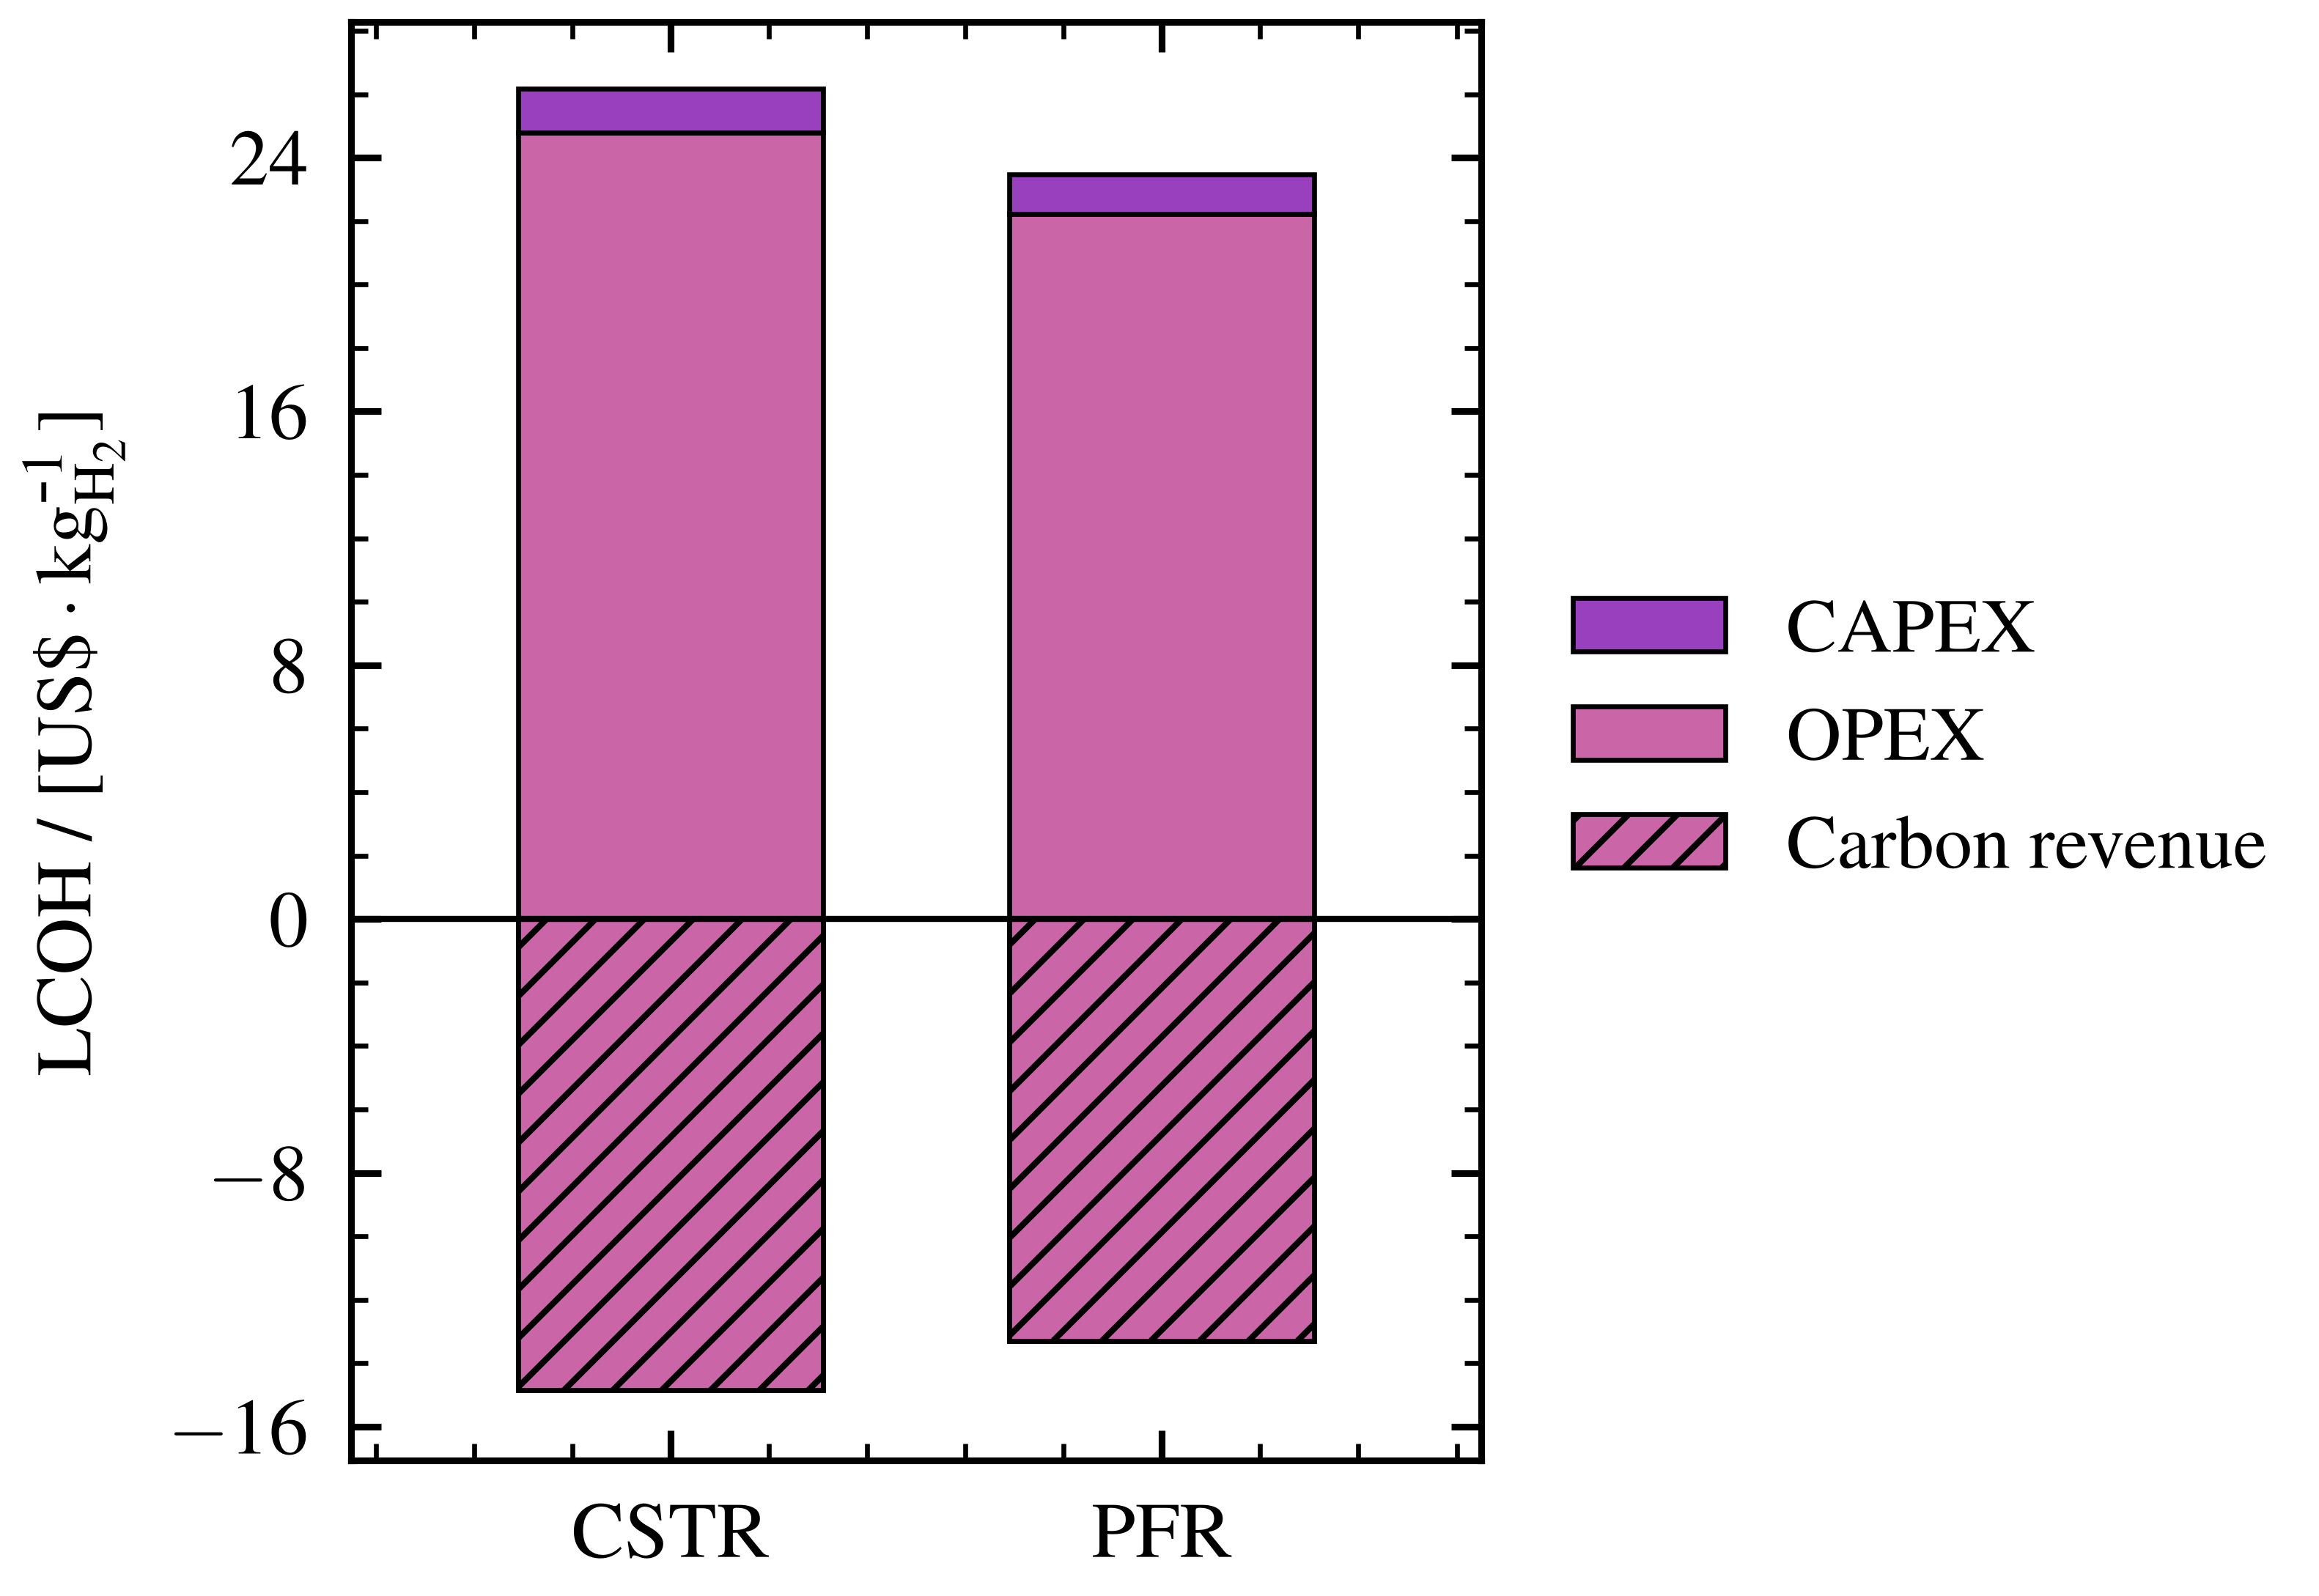

In [17]:
#SI: FIGURE S.5 - LCOH AC
# Same colors, figure size and fonts as the LCOH baseline in Catalyst_Comparison/baseline.ipynb

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

# ---- Style (Catalyst_Comparison/baseline.ipynb) ------------------------------
base_font = 13.0
legend_font = 12.5
scale_factor = 10.5 / 7.5  # figure size as in the comparison plot

lcoh_style = {
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": base_font,
    "axes.labelsize": base_font,
    "xtick.labelsize": base_font,
    "ytick.labelsize": base_font,
    "legend.fontsize": legend_font,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.grid": False,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
}

opex_color = "#CA65A7"  # pink, from the pastel plasma scale
lcoh_colors = {
    "CAPEX":        "#9840BE",  # purple, from the pastel plasma scale
    "OPEX":         opex_color,
    "Side revenue": opex_color,
}
lcoh_hatches = {"Side revenue": "///"}
lcoh_legend_labels = {"Side revenue": "Carbon revenue"}
lcoh_ylabel = r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]"

# ---- Data -------------------------------------------------------------------
levelized_cost = levelized_cost_data(plants=[plant_values_CSTR[idx], plant_values_PFR[idx]])
bars = dict(zip(levelized_cost["xlabels"], levelized_cost["components"]))

# ---- Plot -------------------------------------------------------------------
with plt.style.context(["science", "ieee"]), mpl.rc_context(lcoh_style):
    fig, ax = plt.subplots(figsize=(4 * scale_factor, 2.8 * scale_factor))
    bar_style = dict(width=0.62, edgecolor="black", linewidth=0.8)

    max_positive, min_negative = 0.0, 0.0
    for x, breakdown in enumerate(bars.values()):
        values = [(c, float(v)) for c, v in breakdown.items()]
        positive = sorted([cv for cv in values if cv[1] >= 0], key=lambda cv: cv[1], reverse=True)
        negative = sorted([cv for cv in values if cv[1] < 0], key=lambda cv: abs(cv[1]), reverse=True)

        # Positive stack starts at the bottom of the negative stack: the top shows the net LCOH
        bottom = sum(v for _, v in negative)
        for component, value in positive:
            ax.bar(x, value, bottom=bottom, color=lcoh_colors[component],
                   hatch=lcoh_hatches.get(component), zorder=2, **bar_style)
            bottom += value
        max_positive = max(max_positive, bottom)

        bottom = 0.0
        for component, value in negative:
            ax.bar(x, value, bottom=bottom, color=lcoh_colors[component],
                   hatch=lcoh_hatches.get(component), zorder=3, **bar_style)
            bottom += value
        min_negative = min(min_negative, bottom)

    # x-axis: one tick per reactor
    ax.set_xticks(np.arange(len(bars)))
    ax.set_xticklabels(bars.keys(), fontsize=base_font)
    ax.set_xlim(-0.65, len(bars) - 0.35)

    # y-axis
    ax.set_ylabel(lcoh_ylabel, fontsize=base_font, labelpad=7)
    if min_negative < 0:
        ax.set_ylim(min_negative * 1.15, max_positive * 1.08)
        ax.axhline(0, color="black", linewidth=1.0, zorder=5)
    else:
        ax.set_ylim(0, max_positive * 1.08)
    ax.yaxis.set_major_locator(MultipleLocator(8))
    ax.yaxis.set_minor_locator(MultipleLocator(2))

    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="major", length=4.9, width=1.1, pad=7, labelsize=base_font)
    ax.tick_params(axis="both", which="minor", length=2.8, width=0.8)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1)

    # Legend
    legend_order = ["CAPEX", "OPEX", "Side revenue"]
    legend_handles = [
        Patch(facecolor=lcoh_colors[c], edgecolor="black", linewidth=0.8,
              hatch=lcoh_hatches.get(c), label=lcoh_legend_labels.get(c, c))
        for c in legend_order
        if any(float(b.get(c, 0.0)) != 0.0 for b in bars.values())
    ]
    ax.legend(handles=legend_handles, frameon=False, fontsize=legend_font,
              loc="center left", bbox_to_anchor=(1.02, 0.5))

    fig.tight_layout()
    fig.savefig("figure-s5.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [18]:
# EXTRACT COST BREAKDOWNS

from openpytea.analysis import (
    direct_costs_data,
    fixed_capital_data,
    variable_opex_data,
    fixed_opex_data,
    levelized_cost_data
)


plants = [plant_values_CSTR[idx], plant_values_PFR[idx]]

direct_costs = direct_costs_data(plants=plants, pct=False)

fixed_capital = fixed_capital_data(plants=plants, additional_capex=True)

variable_opex = variable_opex_data(plants=plants, pct=False)

fixed_opex = fixed_opex_data(plants=plants, pct=False)

levelized_cost = levelized_cost_data(plants=plants)

#Average CSTR and PFR

def get_cstr_pfr_avg(data):

    cstr = data["components"][0]
    pfr  = data["components"][1]

    component_names = list(dict.fromkeys(
        list(cstr.keys()) + list(pfr.keys())
    ))

    avg = {
        component: (
            cstr.get(component, 0.0)
            + pfr.get(component, 0.0)
        ) / 2
        for component in component_names
    }

    return cstr, pfr, avg, component_names

#Print breakdown
def print_cost_breakdown(data, title, unit, divisor=1.0, decimals=4):

    cstr, pfr, avg, component_names = get_cstr_pfr_avg(data)

    print()
    print(title)
    print("=" * 105)

    print(
        f"{'Component':<40}"
        f"{'CSTR [' + unit + ']':>21}"
        f"{'PFR [' + unit + ']':>21}"
        f"{'Average [' + unit + ']':>21}"
    )

    print("-" * 105)

    for component in component_names:

        cstr_value = cstr.get(component, 0.0) / divisor
        pfr_value  = pfr.get(component, 0.0) / divisor
        avg_value  = avg.get(component, 0.0) / divisor

        print(
            f"{component:<40}"
            f"{cstr_value:>21,.{decimals}f}"
            f"{pfr_value:>21,.{decimals}f}"
            f"{avg_value:>21,.{decimals}f}"
        )

    total_cstr = sum(cstr.values()) / divisor
    total_pfr  = sum(pfr.values()) / divisor
    total_avg  = (total_cstr + total_pfr) / 2

    print("-" * 105)

    print(
        f"{'TOTAL':<40}"
        f"{total_cstr:>21,.{decimals}f}"
        f"{total_pfr:>21,.{decimals}f}"
        f"{total_avg:>21,.{decimals}f}"
    )


print_cost_breakdown(
    direct_costs,
    title="DIRECT EQUIPMENT COSTS",
    unit="MUSD",
    divisor=1e6
)

print_cost_breakdown(
    fixed_capital,
    title="FIXED CAPITAL COSTS",
    unit="MUSD",
    divisor=1e6
)

print_cost_breakdown(
    variable_opex,
    title="ANNUAL VARIABLE OPEX",
    unit="MUSD/year",
    divisor=1e6
)

print_cost_breakdown(
    fixed_opex,
    title="ANNUAL FIXED OPEX",
    unit="MUSD/year",
    divisor=1e6
)

print_cost_breakdown(
    levelized_cost,
    title="LEVELIZED COST BREAKDOWN",
    unit="$/kg H2",
    divisor=1.0
)


DIRECT EQUIPMENT COSTS
Component                                         CSTR [MUSD]           PFR [MUSD]       Average [MUSD]
---------------------------------------------------------------------------------------------------------
COMP-1                                                 1.1416               0.7883               0.9649
COMP-2                                                30.9143              26.6482              28.7813
MTR-2                                                  5.1984               4.3941               4.7962
COMP-3                                                 0.7629               0.7264               0.7446
COMP-4                                                27.1006              25.9977              26.5491
HX-1                                                   1.9714               0.7901               1.3808
HX-2                                                   0.1254               0.1183               0.1219
HX-3                                  

In [19]:
#SI: FIGURE S.8 - AC BREAKDOWN
# Colors as in the direct-equipment and variable-OPEX comparison plots
# (Catalyst_Comparison/baseline.ipynb); fonts as in the LCOH plot above

import re
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, AutoMinorLocator, ScalarFormatter

# ---- Style ------------------------------------------------------------------
bd_font = 20.0
bd_legend_font = 17.5

bd_style = {
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": bd_font,
    "axes.labelsize": bd_font,
    "xtick.labelsize": bd_font,
    "ytick.labelsize": bd_font,
    "legend.fontsize": bd_legend_font,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.grid": False,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
}

# ---- Colors -----------------------------------------------------------------
# (b) and (c): the exact colors of the comparison plots
direct_colors = {
    "Turbomachinery":      "#4945A5",
    "CO2-capture":         "#9840BE",
    "Reactor & furnace":   "#CA65A7",
    "PSA":                 "#EC9085",
    "Motors & generators": "#FDC265",
    "Heat exchangers":     "#F4FA59",
    "Other":               "#D3D2CD",
}
variable_opex_colors = {
    "Catalyst feed":       "#4945A5",
    "Methane feed":        "#8B40BD",
    "Catalyst separation": "#BD59B1",
    "Carbon disposal fee": "#DD7A95",
    "Electricity":         "#F4A07A",
    "CO2 tax":             "#FECB61",
    "Cooling water":       "#F4FA59",
}


def to_oklab(rgb):
    """sRGB (0-1) -> OKLab, where distance matches perceived color difference."""
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb]
    l, m, s = np.cbrt([
        0.4122214708 * r + 0.5363325363 * g + 0.0514459929 * b,
        0.2119034982 * r + 0.6806995451 * g + 0.1073969566 * b,
        0.0883024619 * r + 0.2817188376 * g + 0.6299787005 * b,
    ])
    return np.array([
        0.2104542553 * l + 0.7936177850 * m - 0.0040720468 * s,
        1.9779984951 * l - 2.4285922050 * m + 0.4505937099 * s,
        0.0259040371 * l + 0.7827717662 * m - 0.8086757660 * s,
    ])


def pastel_colors(n, lighten=0.25):
    """n pastel colors along plasma in equally large (OKLab) steps: the same
    scale as the direct-equipment and variable-OPEX comparison plots."""
    def pastel(x):
        r, g, b, _ = plt.cm.plasma(x)
        return tuple(c + (1.0 - c) * lighten for c in (r, g, b))
    if n == 1:
        return [pastel(0.0)]
    xs = np.linspace(0.0, 1.0, 1001)
    lab = np.array([to_oklab(pastel(x)) for x in xs])
    distance = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(lab, axis=0), axis=1))])
    positions = np.interp(np.linspace(0.0, distance[-1], n), distance, xs)
    return [pastel(x) for x in positions]


# ---- Data -------------------------------------------------------------------
bd_plants = [plant_values_CSTR[idx], plant_values_PFR[idx]]
bd_xlabels = ["CSTR", "PFR"]

# Direct equipment: same groups as the comparison plot
direct_cost_groups = [
    (r"^COMP[-_ ]?\d+$",           "Turbomachinery"),
    (r"^MTR[-_ ]?\d+$",            "Motors & generators"),
    (r"^HX[-_ ]?\d+$",             "Heat exchangers"),
    (r"^COOLER[-_ ]?\d+$",         "Heat exchangers"),
    (r"REACTOR|^(CSTR|PFR)$",      "Reactor & furnace"),
    (r"FURNACE",                   "Reactor & furnace"),
    (r"CYCLONE",                   "Other"),
    (r"TURBINE",                   "Turbomachinery"),
    (r"PUMP",                      "Turbomachinery"),
    (r"CO2.*CAPTURE|CAPTURE.*CO2", "CO2-capture"),
    (r"PSA",                       "PSA"),
    (r"GENERATOR",                 "Motors & generators"),
]


def direct_cost_group(name):
    upper = name.upper().strip()
    for pattern, group in direct_cost_groups:
        if re.search(pattern, upper):
            return group
    return name


def to_bars(data, group_of=None, divisor=1e6):
    """[{component: value / divisor}, ...], one dict per bar. Components that
    are zero in every bar (e.g. interest on working capital) are dropped."""
    bars = []
    for components in data["components"]:
        bar = {}
        for name, value in components.items():
            key = group_of(name) if group_of else name
            bar[key] = bar.get(key, 0.0) + float(value) / divisor
        bars.append(bar)
    keep = {c for bar in bars for c, v in bar.items() if v != 0.0}
    return [{c: v for c, v in bar.items() if c in keep} for bar in bars]


fixed_capital_bars = to_bars(fixed_capital_data(plants=bd_plants, additional_capex=True))
direct_cost_bars = to_bars(direct_costs_data(plants=bd_plants), group_of=direct_cost_group)
variable_opex_bars = to_bars(variable_opex_data(plants=bd_plants))
fixed_opex_bars = to_bars(fixed_opex_data(plants=bd_plants))

# ---- Labels -----------------------------------------------------------------
bd_labels = {
    "CO2-capture":         r"CO$_2$ capture",
    "CO2 tax":             r"CO$_2$ tax",
    "Reactor & furnace":   r"Reactor \& furnace",
    "Motors & generators": r"Motors \& generators",
}
per_year = r"\,$\cdot$\,year$^{\mbox{-}1}$"


# ---- Stacked-bar panel ------------------------------------------------------
def plot_breakdown(ax, bars, ylabel, colors=None):
    """Stacked bars (largest component at the bottom), legend on the right
    listing the components from largest to smallest."""
    totals = {}
    for bar in bars:
        for c, v in bar.items():
            totals[c] = totals.get(c, 0.0) + abs(v)
    order = sorted(totals, key=totals.get, reverse=True)
    if colors is None:  # spread the components over the pastel plasma scale
        colors = dict(zip(order, pastel_colors(len(order))))

    def color_of(c):
        return colors.get(c, "#D3D2CD")

    bar_style = dict(width=0.62, edgecolor="black", linewidth=0.8, zorder=2)
    top = 0.0
    for x, bar in enumerate(bars):
        bottom = 0.0
        for c, v in sorted(bar.items(), key=lambda cv: cv[1], reverse=True):
            ax.bar(x, v, bottom=bottom, color=color_of(c), **bar_style)
            bottom += v
        top = max(top, bottom)

    ax.set_xticks(np.arange(len(bars)))
    ax.set_xticklabels(bd_xlabels)
    ax.set_xlim(-0.65, len(bars) - 0.35)
    ax.set_ylim(0, top * 1.08)
    ax.set_ylabel(ylabel, labelpad=9)

    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))
    formatter = ScalarFormatter(useOffset=False)
    formatter.set_scientific(False)
    ax.yaxis.set_major_formatter(formatter)

    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.tick_params(axis="x", which="minor", bottom=False, top=False)
    ax.tick_params(axis="both", which="major", length=6.5, width=1.2, pad=8)
    ax.tick_params(axis="both", which="minor", length=3.5, width=0.9)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.2)

    handles = [Patch(facecolor=color_of(c), edgecolor="black", linewidth=0.8,
                     label=bd_labels.get(c, c)) for c in order]
    ax.legend(handles=handles, frameon=False, loc="center left", bbox_to_anchor=(1.03, 0.5),
              labelspacing=0.45, handlelength=1.4, handletextpad=0.6)


# ---- Four panels ------------------------------------------------------------
with plt.style.context(["science", "ieee"]), mpl.rc_context(bd_style):
    fig, axs = plt.subplots(2, 2, figsize=(14.5, 10.5), layout="constrained")
    fig.get_layout_engine().set(w_pad=0.05, h_pad=0.05, wspace=0.0, hspace=0.0)

    panels = [
        (fixed_capital_bars, r"Fixed capital costs / [millions US\$]", None),
        (direct_cost_bars, r"Direct equipment costs / [millions US\$]", direct_colors),
        (variable_opex_bars, r"Variable OPEX / [millions US\$" + per_year + "]", variable_opex_colors),
        (fixed_opex_bars, r"Fixed OPEX / [millions US\$" + per_year + "]", None),
    ]
    for ax, (bars, ylabel, colors), tag in zip(axs.flat, panels, "abcd"):
        plot_breakdown(ax, bars, ylabel, colors)
        ax.text(0.5, -0.11, f"({tag})", transform=ax.transAxes, ha="center", va="top")

    fig.savefig("figure-s8.pdf", format="pdf", dpi=500, bbox_inches="tight")

plt.show()

In [20]:
# Save cost breakdowns to JSON
import json
from pathlib import Path

# Calculate average costs
_, _, avg_direct_costs, _   = get_cstr_pfr_avg(direct_costs)
_, _, avg_fixed_capital, _  = get_cstr_pfr_avg(fixed_capital)
_, _, avg_variable_opex, _  = get_cstr_pfr_avg(variable_opex)
_, _, avg_fixed_opex, _     = get_cstr_pfr_avg(fixed_opex)
_, _, avg_levelized_cost, _ = get_cstr_pfr_avg(levelized_cost)

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["catalysts", "benchmarks"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "catalysts" / "ac" / "results" / "tea"
results_dir.mkdir(parents=True, exist_ok=True)

# JSON files
file_direct_costs   = results_dir / "Direct_costs_avg.json"
file_fixed_capital  = results_dir / "Fixed_capital_avg.json"
file_variable_opex  = results_dir / "Variable_opex_avg.json"
file_fixed_opex     = results_dir / "Fixed_opex_avg.json"
file_levelized_cost = results_dir / "LCOH_avg.json"

# Save JSON results
with open(file_direct_costs, "w") as f:   json.dump({k: float(v) for k, v in avg_direct_costs.items()}, f, indent=4)
with open(file_fixed_capital, "w") as f:  json.dump({k: float(v) for k, v in avg_fixed_capital.items()}, f, indent=4)
with open(file_variable_opex, "w") as f:  json.dump({k: float(v) for k, v in avg_variable_opex.items()}, f, indent=4)
with open(file_fixed_opex, "w") as f:     json.dump({k: float(v) for k, v in avg_fixed_opex.items()}, f, indent=4)
with open(file_levelized_cost, "w") as f: json.dump({k: float(v) for k, v in avg_levelized_cost.items()}, f, indent=4)

print(f"JSON files saved in: {results_dir.resolve()}")

JSON files saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\ACMP\Results_TEA


In [21]:
# SPECIFIC CO2 EMISSIONS - CH4 HEATING WITH CCS

import pandas as pd

#Inputs
h2_production_daily = 100_000  # kg H2/day = 100 TPD
h2_production_hourly = h2_production_daily / 24  # kg H2/h

electricity_co2_factor = 0.283  # kg CO2/kWh

elec_mecc_eff = 0.90  # Electrical-to-mechanical efficiency of compressor
mecc_elec_eff = 0.90  # Mechanical-to-electrical efficiency of the generator

#Function for co2 emissions

def calculate_specific_co2_ccs(csv_path):

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    # Direct emissions
    co2_before_ccs_flow = df["CO2 Emission [kg/h]"].iloc[0] if "CO2 Emission [kg/h]" in df.columns else 0.0
    co2_direct_flow = df["CO2 with CCS [kg/h]"].iloc[0] if "CO2 with CCS [kg/h]" in df.columns else 0.0

    if pd.isna(co2_before_ccs_flow):
        co2_before_ccs_flow = 0.0

    if pd.isna(co2_direct_flow):
        co2_direct_flow = 0.0

    co2_captured_flow = co2_before_ccs_flow - co2_direct_flow

    # electricity consumption
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]

    mtr_1_pwr = comp_1_pwr / elec_mecc_eff
    mtr_2_pwr = comp_2_pwr / elec_mecc_eff
    mtr_3_pwr = comp_3_pwr / elec_mecc_eff
    mtr_4_pwr = comp_4_pwr / elec_mecc_eff

    electricity_power = (
        mtr_1_pwr
        + mtr_2_pwr
        + mtr_3_pwr
        + mtr_4_pwr
        + turbine_power * mecc_elec_eff
    )

    # Indirect emissions
    co2_electric_flow = electricity_power * electricity_co2_factor

    # total emissions co2
    co2_total_flow = co2_direct_flow + co2_electric_flow

    # specific emissions co2
    co2_direct = co2_direct_flow / h2_production_hourly
    co2_electric = co2_electric_flow / h2_production_hourly
    co2_h2 = co2_total_flow / h2_production_hourly

    return {
        "h2_production_hourly": h2_production_hourly,
        "electricity_power": electricity_power,
        "co2_before_ccs_flow": co2_before_ccs_flow,
        "co2_captured_flow": co2_captured_flow,
        "co2_direct_flow": co2_direct_flow,
        "co2_electric_flow": co2_electric_flow,
        "co2_total_flow": co2_total_flow,
        "co2_direct": co2_direct,
        "co2_electric": co2_electric,
        "co2_h2": co2_h2
    }


def calculate_co2_dataset(csv_files):

    return {
        temperature: calculate_specific_co2_ccs(path)
        for temperature, path in csv_files.items()
    }


co2_PFR_ccs = calculate_co2_dataset(csv_files_PFR_Tchange_DA02_W210000)
co2_CSTR_ccs = calculate_co2_dataset(csv_files_CSTR_Tchange_DA02_W210000)

selected_temperature = 825

pfr = co2_PFR_ccs[selected_temperature]
cstr = co2_CSTR_ccs[selected_temperature]

#Average
co2_direct_avg_ccs = (pfr["co2_direct"] + cstr["co2_direct"]) / 2
co2_electric_avg_ccs = (pfr["co2_electric"] + cstr["co2_electric"]) / 2
co2_h2_avg_ccs = (pfr["co2_h2"] + cstr["co2_h2"]) / 2


# CSTR
print()
print(f"CSTR — {selected_temperature} °C")
print("-" * 75)

print(f"Net electricity consumption:    {cstr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {cstr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {cstr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {cstr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {cstr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {cstr['co2_total_flow']:>12,.4f} kg CO2/h")

# PFR
print()
print(f"PFR — {selected_temperature} °C")
print("-" * 75)

print(f"Net electricity consumption:    {pfr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {pfr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {pfr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {pfr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {pfr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {pfr['co2_total_flow']:>12,.4f} kg CO2/h")

# AVERAGE
print()
print("AVERAGE PFR/CSTR")
print("-" * 75)

print(f"Specific direct emissions:      {co2_direct_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"Specific electricity emissions: {co2_electric_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"TOTAL specific emissions:       {co2_h2_avg_ccs:>12.6f} kg CO2/kg H2")


CSTR — 825 °C
---------------------------------------------------------------------------
Net electricity consumption:       11,194.21 kW
CO2 before CCS:                  20,457.5559 kg CO2/h
CO2 captured:                    18,411.8003 kg CO2/h
Direct CO2 after CCS:             2,045.7556 kg CO2/h
Electricity CO2 emissions:        3,167.9607 kg CO2/h
Total CO2 emissions:              5,213.7163 kg CO2/h

PFR — 825 °C
---------------------------------------------------------------------------
Net electricity consumption:        9,803.86 kW
CO2 before CCS:                  19,227.5230 kg CO2/h
CO2 captured:                    17,304.7707 kg CO2/h
Direct CO2 after CCS:             1,922.7523 kg CO2/h
Electricity CO2 emissions:        2,774.4923 kg CO2/h
Total CO2 emissions:              4,697.2446 kg CO2/h

AVERAGE PFR/CSTR
---------------------------------------------------------------------------
Specific direct emissions:          0.476221 kg CO2/kg H2
Specific electricity emissions:

In [22]:
# Save CO2 emissions JSON CH4 CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["catalysts", "benchmarks"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "catalysts" / "ac" / "results" / "tea"
results_dir.mkdir(parents=True, exist_ok=True)

results_file = results_dir / "CO2_results.json"

# Load existing results
if results_file.exists():
    with open(results_file, "r") as f:
        co2_results = json.load(f)
else:
    co2_results = {}

# Update results
co2_results["CH4_with_CCS"] = co2_h2_avg_ccs

# Save JSON
with open(results_file, "w") as f:
    json.dump(co2_results, f, indent=4)

print(f"JSON saved in: {results_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\ACMP\Results_TEA\CO2_results.json


In [23]:
#SENSITIVITY ANALYSES

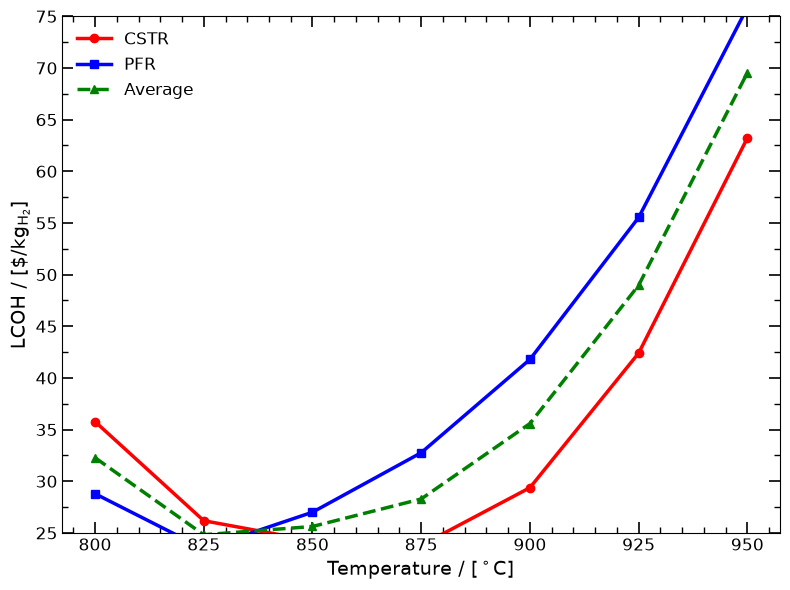


LCOH VS TEMPERATURE
  Temperature [°C]      CSTR [$/kg H2]       PFR [$/kg H2]     Average [$/kg H2]
--------------------------------------------------------------------------------------
            800.00           35.770537           28.792021             32.281279
            825.00           26.180684           23.464131             24.822408
            850.00           24.240014           27.003795             25.621904
            875.00           23.808419           32.764331             28.286375
            900.00           29.379071           41.792835             35.585953
            925.00           42.406515           55.533283             48.969899
            950.00           63.229159           75.857344             69.543252

TEMPERATURES:
[800 825 850 875 900 925 950]

LCOH CSTR:
[35.77053687 26.18068448 24.24001351 23.80841874 29.37907142 42.40651505
 63.22915881]

LCOH PFR:
[28.79202139 23.46413073 27.00379471 32.76433123 41.79283482 55.53328261
 75.85734442]

L

In [24]:
# LCOH PLOT vs TEMPERATURE

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.style.use('default')

# Conversione in array numpy
temperatures = np.asarray(temperatures)
lcoh_values_CSTR = np.asarray(lcoh_values_CSTR)
lcoh_values_PFR = np.asarray(lcoh_values_PFR)

# Average LCOH
lcoh_values_mean = (
    lcoh_values_CSTR + lcoh_values_PFR
) / 2

#Plot
fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    lcoh_values_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    lcoh_values_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

# Curve AVERAGE
ax.plot(
    temperatures,
    lcoh_values_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=14
)

ax.set_ylabel(
    r"LCOH / [\$/kg$_{\mathrm{H}_2}$]",
    fontsize=14
)

ax.xaxis.set_major_locator(
    MultipleLocator(25)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(5)
)

ax.set_ylim(25, 75)

ax.yaxis.set_major_locator(
    MultipleLocator(5)
)

ax.yaxis.set_minor_locator(
    MultipleLocator(2.5)
)

ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

#Print values

print()
print("LCOH VS TEMPERATURE")
print("=" * 86)

print(
    f"{'Temperature [°C]':>18}"
    f"{'CSTR [$/kg H2]':>20}"
    f"{'PFR [$/kg H2]':>20}"
    f"{'Average [$/kg H2]':>22}"
)

print("-" * 86)

for temperature, lcoh_cstr, lcoh_pfr, lcoh_average in zip(
    temperatures,
    lcoh_values_CSTR,
    lcoh_values_PFR,
    lcoh_values_mean
):
    print(
        f"{temperature:>18.2f}"
        f"{lcoh_cstr:>20.6f}"
        f"{lcoh_pfr:>20.6f}"
        f"{lcoh_average:>22.6f}"
    )

print("=" * 86)

print("\nTEMPERATURES:")
print(temperatures)

print("\nLCOH CSTR:")
print(lcoh_values_CSTR)

print("\nLCOH PFR:")
print(lcoh_values_PFR)

print("\nLCOH AVERAGE:")
print(lcoh_values_mean)

In [25]:
# Save JSON of average temperature
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["catalysts", "benchmarks"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "catalysts" / "ac" / "results" / "tea"
results_dir.mkdir(parents=True, exist_ok=True)

file_lcoh_temperature = results_dir / "LCOH_temperature.json"

# LCOH at different solid carbon selling prices (baseline price: 1.5 US$/kg)
import numpy as np
from copy import deepcopy

carbon_prices = [0.5, 1.5, 2.5]  # US$/kg


def lcoh_at_carbon_price(plant, carbon_price):
    """LCOH of a copy of the plant, with only the carbon selling price changed."""
    plant = deepcopy(plant)
    plant.plant_products["carbon"]["price"] = carbon_price
    return float(np.asarray(plant.calculate_levelized_cost(print_results=False)).item())


# Average of PFR and CSTR, for every temperature, at every carbon price
lcoh_by_carbon_price = {
    str(price): [
        (lcoh_at_carbon_price(pfr, price) + lcoh_at_carbon_price(cstr, price)) / 2
        for pfr, cstr in zip(plant_values_PFR, plant_values_CSTR)
    ]
    for price in carbon_prices
}

# Prepare JSON results
lcoh_temperature_results = {
    "temperature": [float(value) for value in temperatures],
    "lcoh_average": [float(value) for value in lcoh_values_mean],
    # keys are carbon prices in US$/kg; each list follows "temperature"
    "lcoh_average_by_carbon_price": lcoh_by_carbon_price,
}

# Save JSON
with open(file_lcoh_temperature, "w") as f:
    json.dump(lcoh_temperature_results, f, indent=4)

print(f"JSON saved in: {file_lcoh_temperature.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\ACMP\Results_TEA\LCOH_temperature.json


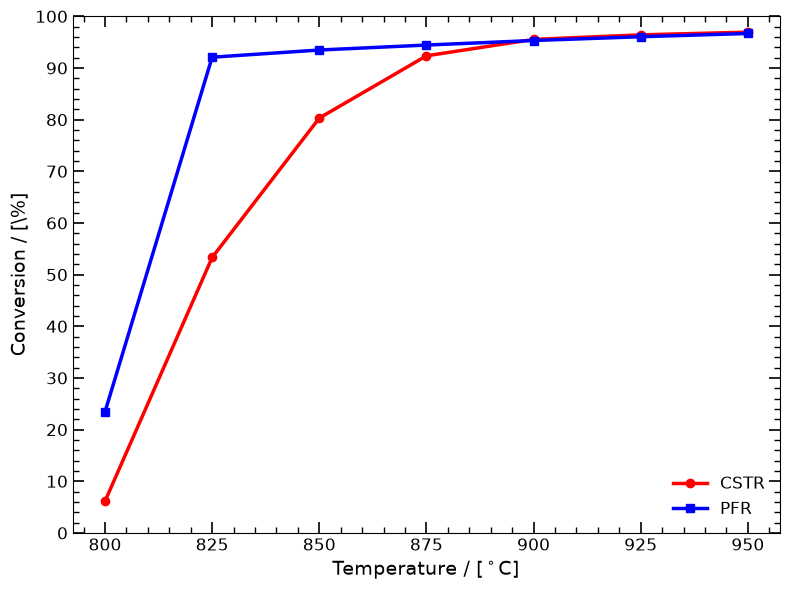

In [26]:
# CONVERSION PLOT vs TEMPERATURE

import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import MultipleLocator

plt.style.use("default")


fig, ax = plt.subplots(figsize=(8, 6))

#CSTR
ax.plot(
    temperatures,
    conversion_CSTR,
    "-o",
    color="red",
    linewidth=2.5,
    markersize=6,
    label="CSTR"
)

#PFR
ax.plot(
    temperatures,
    conversion_PFR,
    "-s",
    color="blue",
    linewidth=2.5,
    markersize=6,
    label="PFR"
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=14
)

ax.set_ylabel(
    r"Conversion / [\%]",
    fontsize=14
)

ax.xaxis.set_major_locator(
    MultipleLocator(25)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(5)
)

ax.set_ylim(0, 100)

ax.yaxis.set_major_locator(
    MultipleLocator(10)
)

ax.yaxis.set_minor_locator(
    MultipleLocator(2)
)

ax.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12,
    loc="lower right"
)

plt.tight_layout()

plt.show()


In [27]:
#SI: FIGURE S.13 - AC TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots

from pathlib import Path
from matplotlib.ticker import MultipleLocator, FixedLocator

scale = 1.45

plt.style.use(["science", "ieee"])

tick_font       = 21.0 * scale
axis_label_font = 22.5 * scale
legend_font     = 18.0 * scale
panel_font      = 21.5 * scale

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

temperatures = np.asarray(temperatures, dtype=float)

lcoh_values_CSTR = np.asarray(lcoh_values_CSTR, dtype=float)
lcoh_values_PFR  = np.asarray(lcoh_values_PFR, dtype=float)
lcoh_values_mean = (lcoh_values_CSTR + lcoh_values_PFR) / 2.0

conversion_CSTR = np.asarray(conversion_CSTR, dtype=float)
conversion_PFR  = np.asarray(conversion_PFR, dtype=float)

#Figure
fig, axs = plt.subplots(
    2,
    2,
    figsize=(15.4 * scale, 11.2 * scale)
)

ax_a = axs[0, 0]
ax_b = axs[0, 1]


axs[1, 0].remove()
axs[1, 1].remove()

def style_axes(ax):

    ax.tick_params(
        axis="x",
        which="major",
        direction="in",
        top=True,
        bottom=True,
        labelsize=tick_font,
        colors="black",
        length=5.8 * scale,
        width=1.1 * scale,
        pad=7 * scale
    )

    ax.tick_params(
        axis="y",
        which="major",
        direction="in",
        left=True,
        right=True,
        labelsize=tick_font,
        colors="black",
        length=5.8 * scale,
        width=1.1 * scale,
        pad=7 * scale
    )

    ax.tick_params(
        axis="x",
        which="minor",
        direction="in",
        top=True,
        bottom=True,
        colors="black",
        length=3.2 * scale,
        width=0.8 * scale
    )

    ax.tick_params(
        axis="y",
        which="minor",
        direction="in",
        left=True,
        right=True,
        colors="black",
        length=3.2 * scale,
        width=0.8 * scale
    )

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1 * scale)

#Panel A LCOH
ax_a.plot(
    temperatures,
    lcoh_values_CSTR,
    "-o",
    color="red",
    linewidth=2.5 * scale,
    markersize=6 * scale,
    label="CSTR"
)

ax_a.plot(
    temperatures,
    lcoh_values_PFR,
    "-s",
    color="blue",
    linewidth=2.5 * scale,
    markersize=6 * scale,
    label="PFR"
)

ax_a.plot(
    temperatures,
    lcoh_values_mean,
    "--^",
    color="green",
    linewidth=2.5 * scale,
    markersize=6 * scale,
    label="Average"
)

ax_a.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font,
    labelpad=8 * scale
)

ax_a.set_ylabel(
    r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]",
    fontsize=axis_label_font,
    labelpad=10 * scale
)

ax_a.set_ylim(18, 82)

ax_a.xaxis.set_major_locator(MultipleLocator(25))
ax_a.xaxis.set_minor_locator(MultipleLocator(5))

ax_a.yaxis.set_major_locator(
    FixedLocator([20, 30, 40, 50, 60, 70, 80])
)
ax_a.yaxis.set_minor_locator(MultipleLocator(2.5))

legend_a = ax_a.legend(
    loc="best",
    fontsize=legend_font,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    facecolor="white",
    edgecolor="0.50",
    handlelength=1.5 * scale,
    handletextpad=0.4 * scale,
    borderpad=0.35 * scale,
    labelspacing=0.28 * scale
)

legend_a.get_frame().set_linewidth(0.8 * scale)

style_axes(ax_a)

#Panel B CONVERSION
ax_b.plot(
    temperatures,
    conversion_CSTR,
    "-o",
    color="red",
    linewidth=2.25 * scale,
    markersize=5.4 * scale,
    label="CSTR"
)

ax_b.plot(
    temperatures,
    conversion_PFR,
    "-s",
    color="blue",
    linewidth=2.6 * scale,
    markersize=6 * scale,
    label="PFR"
)

ax_b.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font,
    labelpad=8 * scale
)

ax_b.set_ylabel(
    r"Conversion / [\%]",
    fontsize=axis_label_font,
    labelpad=10 * scale
)

ax_b.set_ylim(0, 100)

ax_b.xaxis.set_major_locator(MultipleLocator(25))
ax_b.xaxis.set_minor_locator(MultipleLocator(5))

ax_b.yaxis.set_major_locator(
    FixedLocator([0, 15, 30, 45, 60, 75, 90])
)
ax_b.yaxis.set_minor_locator(MultipleLocator(5))

legend_b = ax_b.legend(
    loc="lower right",
    fontsize=legend_font,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    facecolor="white",
    edgecolor="0.50",
    handlelength=1.5 * scale,
    handletextpad=0.4 * scale,
    borderpad=0.35 * scale,
    labelspacing=0.28 * scale
)

legend_b.get_frame().set_linewidth(0.8 * scale)

style_axes(ax_b)

#Layout
ax_a.text(
    0.5,
    -0.195,
    r"(a)",
    transform=ax_a.transAxes,
    ha="center",
    va="top",
    fontsize=panel_font
)

ax_b.text(
    0.5,
    -0.195,
    r"(b)",
    transform=ax_b.transAxes,
    ha="center",
    va="top",
    fontsize=panel_font
)

fig.subplots_adjust(
    left=0.085,
    right=0.985,
    bottom=0.090,
    top=0.985,
    wspace=0.24,
    hspace=0.36
)

fig.savefig("AC_twopanel_temperature.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()


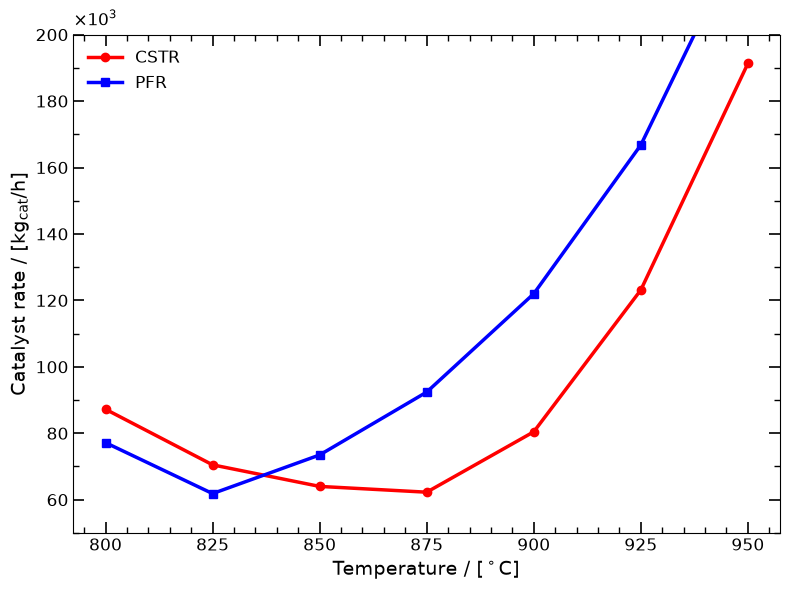

In [28]:
# CATALYST RATE PLOT vs TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

plt.style.use('default')


fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    catrate_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    catrate_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=14
)

ax.set_ylabel(
    r"Catalyst rate / [kg$_{\mathrm{cat}}$/h]",
    fontsize=14
)

ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))


ax.set_ylim(50000, 200000)
ax.yaxis.set_major_locator(MultipleLocator(20000))
ax.yaxis.set_minor_locator(MultipleLocator(10000))


ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f'{y / 1000:g}')
)


ax.text(
    0.0,
    1.01,
    r'$\times 10^3$',
    transform=ax.transAxes,
    fontsize=12,
    ha='left',
    va='bottom'
)

ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

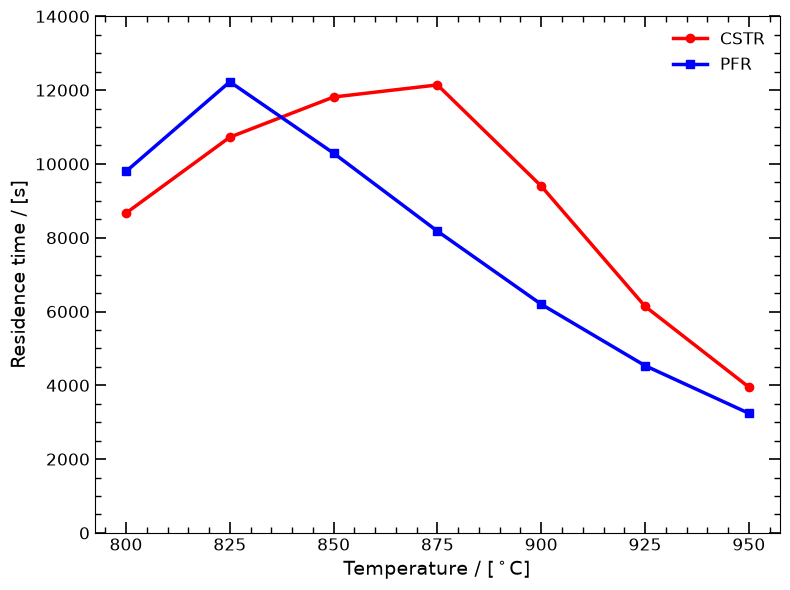

In [29]:
# RESIDENCE TIME PLOT vs TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.style.use('default')

fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    residence_time_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    residence_time_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

ax.set_xlabel(r"Temperature / [$^\circ$C]", fontsize=14)
ax.set_ylabel(r"Residence time / [s]", fontsize=14)

ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))

ax.set_ylim(0, 14000)
ax.yaxis.set_major_locator(MultipleLocator(2000))
ax.yaxis.set_minor_locator(MultipleLocator(500))

ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

In [30]:
# LCOH SWEEPS AT T = 825 °C: CATALYST AMOUNT AND DEACTIVATION FACTOR
# Each sweep keeps its own results, so these plots don't depend on which
# sweep the PFR/CSTR loop cells above last ran (they run the temperature sweep).
import numpy as np


def lcoh_sweep(csv_files_PFR, csv_files_CSTR):
    """Run the PFR and CSTR TEA for every case in a sweep.

    Both dicts map the swept value (e.g. catalyst amount) to a simulation CSV.
    Returns the swept values and the LCOH of each reactor, in the same order.
    """
    if list(csv_files_PFR) != list(csv_files_CSTR):
        raise ValueError("PFR and CSTR sweeps must cover the same values.")

    return {
        "values": np.asarray(list(csv_files_PFR), dtype=float),
        "lcoh_PFR": np.asarray(
            [run_tea_pfr(path)["lcoh_pfr"] for path in csv_files_PFR.values()],
            dtype=float,
        ),
        "lcoh_CSTR": np.asarray(
            [run_tea_cstr(path)["lcoh_cstr"] for path in csv_files_CSTR.values()],
            dtype=float,
        ),
    }


# Fixed T (825 °C) and a (0.2)
sweep_catalyst_amount = lcoh_sweep(
    csv_files_PFR_T825_DA02_Wchange, csv_files_CSTR_T825_DA02_Wchange
)

# Fixed T (825 °C) and w (210000 kg)
sweep_deactivation = lcoh_sweep(
    csv_files_PFR_T825_DAchange_W210000, csv_files_CSTR_T825_DAchange_W210000
)

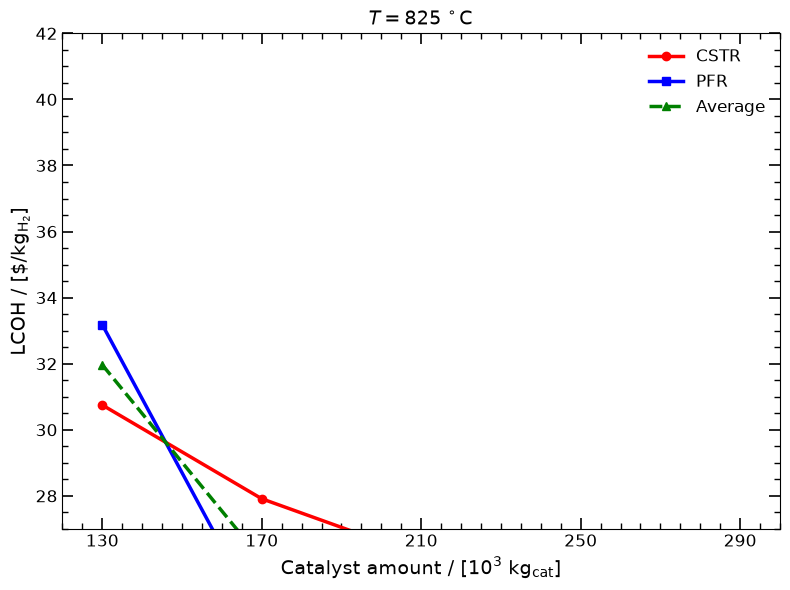

In [31]:
# LCOH VS CATALYST AMOUNT AT T = 825 °C
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

plt.style.use('default')

catalyst_amounts_array = sweep_catalyst_amount["values"]

lcoh_catamount_CSTR_array = sweep_catalyst_amount["lcoh_CSTR"]
lcoh_catamount_PFR_array = sweep_catalyst_amount["lcoh_PFR"]

#Avergae LCOH
lcoh_catamount_mean = (
    lcoh_catamount_CSTR_array
    + lcoh_catamount_PFR_array
) / 2


catalyst_amounts_plot = catalyst_amounts_array / 1e3

fig, ax = plt.subplots(figsize=(8, 6))

#PFR Curve
ax.plot(
    catalyst_amounts_plot,
    lcoh_catamount_CSTR_array,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

#CSTR Curve
ax.plot(
    catalyst_amounts_plot,
    lcoh_catamount_PFR_array,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

#Average Curve
ax.plot(
    catalyst_amounts_plot,
    lcoh_catamount_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)


ax.set_xlabel(
    r"Catalyst amount / [$10^3$ kg$_{\mathrm{cat}}$]",
    fontsize=14
)

ax.set_ylabel(
    r"LCOH / [\$/kg$_{\mathrm{H}_2}$]",
    fontsize=14
)

ax.set_title(
    r"$T = 825\,^\circ$C",
    fontsize=14
)

ax.set_xlim(120, 300)

ax.set_xticks(catalyst_amounts_plot)

ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))

ax.xaxis.set_minor_locator(MultipleLocator(5))

ax.set_ylim(27, 42)

ax.yaxis.set_major_locator(MultipleLocator(2))

ax.yaxis.set_minor_locator(MultipleLocator(0.5))


ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)


ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()

plt.show()

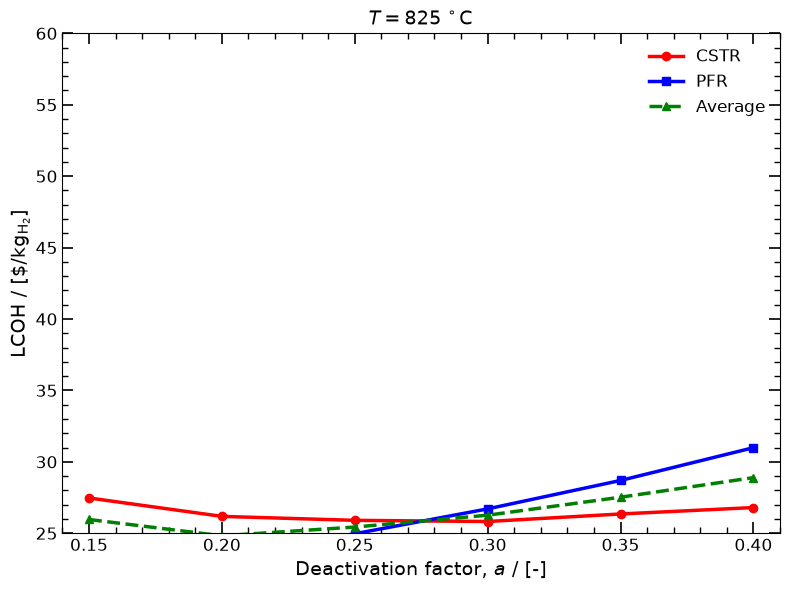

In [32]:
# LCOH VS DEACTIVATION FACTOR
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

plt.style.use('default')

deactivation_factors_array = sweep_deactivation["values"]

lcoh_deactivation_CSTR_array = sweep_deactivation["lcoh_CSTR"]
lcoh_deactivation_PFR_array = sweep_deactivation["lcoh_PFR"]


#Average CSTR/PFR
lcoh_deactivation_mean = (
    lcoh_deactivation_CSTR_array
    + lcoh_deactivation_PFR_array
) / 2

fig, ax = plt.subplots(figsize=(8, 6))


ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_CSTR_array,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_PFR_array,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)


ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)

ax.set_xlabel(
    r"Deactivation factor, $a$ / [-]",
    fontsize=14
)

ax.set_ylabel(
    r"LCOH / [\$/kg$_{\mathrm{H}_2}$]",
    fontsize=14
)


ax.set_title(
    r"$T = 825\,^\circ$C",
    fontsize=14
)


ax.set_xlim(0.14, 0.41)
ax.set_xticks(deactivation_factors_array)

ax.xaxis.set_major_formatter(
    FormatStrFormatter('%.2f')
)

ax.xaxis.set_minor_locator(
    MultipleLocator(0.01)
)

ax.set_ylim(25, 60)

ax.yaxis.set_major_locator(
    MultipleLocator(5)
)

ax.yaxis.set_minor_locator(
    MultipleLocator(1)
)

ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()

plt.show()

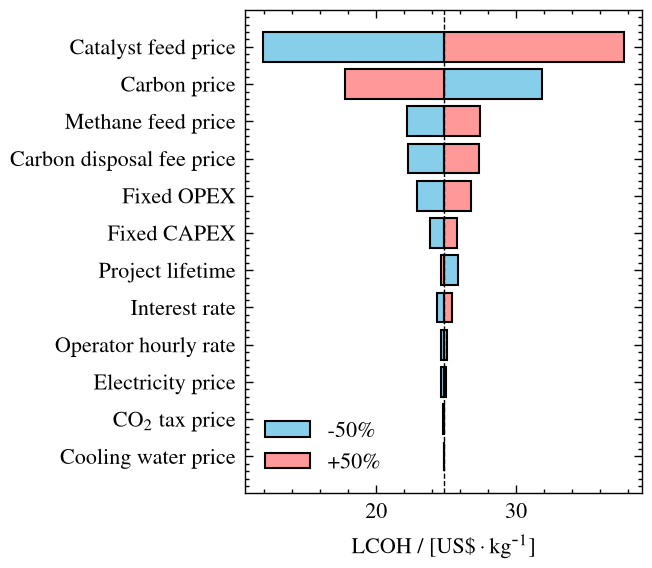

In [33]:
#SI: FIGURE S.16 - TORNADO PLOT AC
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

tornado_PFR = tornado_data(plant=plant_values_PFR[idx], plus_minus_value=0.5, metric="LCOP")
tornado_CSTR = tornado_data(plant=plant_values_CSTR[idx], plus_minus_value=0.5, metric="LCOP")

#Average CSTR/PFR
def average_tornado_data(data_pfr, data_cstr):

    pfr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_pfr["factors"], data_pfr["lows"], data_pfr["highs"], data_pfr["labels"]
        )
    }

    cstr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_cstr["factors"], data_cstr["lows"], data_cstr["highs"], data_cstr["labels"]
        )
    }

    if set(pfr_results) != set(cstr_results):
        raise ValueError("PFR and CSTR do not contain the same sensitivity parameters.")

    averaged_results = []

    for factor in pfr_results:
        average_low = (pfr_results[factor]["low"] + cstr_results[factor]["low"]) / 2
        average_high = (pfr_results[factor]["high"] + cstr_results[factor]["high"]) / 2
        label = pfr_results[factor]["label"].replace("CO2", r"CO$_2$")
        averaged_results.append((factor, average_low, average_high, label))

    averaged_results.sort(key=lambda result: abs(result[2] - result[1]))

    return {
        "factors": [result[0] for result in averaged_results],
        "lows": np.array([result[1] for result in averaged_results]),
        "highs": np.array([result[2] for result in averaged_results]),
        "labels": [result[3] for result in averaged_results],
        "base_value": (data_pfr["base_value"] + data_cstr["base_value"]) / 2,
        "plus_minus_value": data_pfr["plus_minus_value"],
        "metric": "LCOP",
        "xlabel": r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]"
    }


tornado_average = average_tornado_data(tornado_PFR, tornado_CSTR)

# The plot cells above call plt.style.use("default"), which switches LaTeX off.
# The \mbox in the LCOH label needs LaTeX, so restore the OpenPyTEA style first.
plt.style.use(["science", "ieee"])
mpl.rcParams.update({"text.usetex": True, "figure.dpi": 200, "savefig.dpi": 600})

fig, ax = plot_tornado(tornado_average)

ax.set_xlabel(r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]")
ax.set_title("")

fig.savefig("figure-s16.pdf", format="pdf")

plt.show()

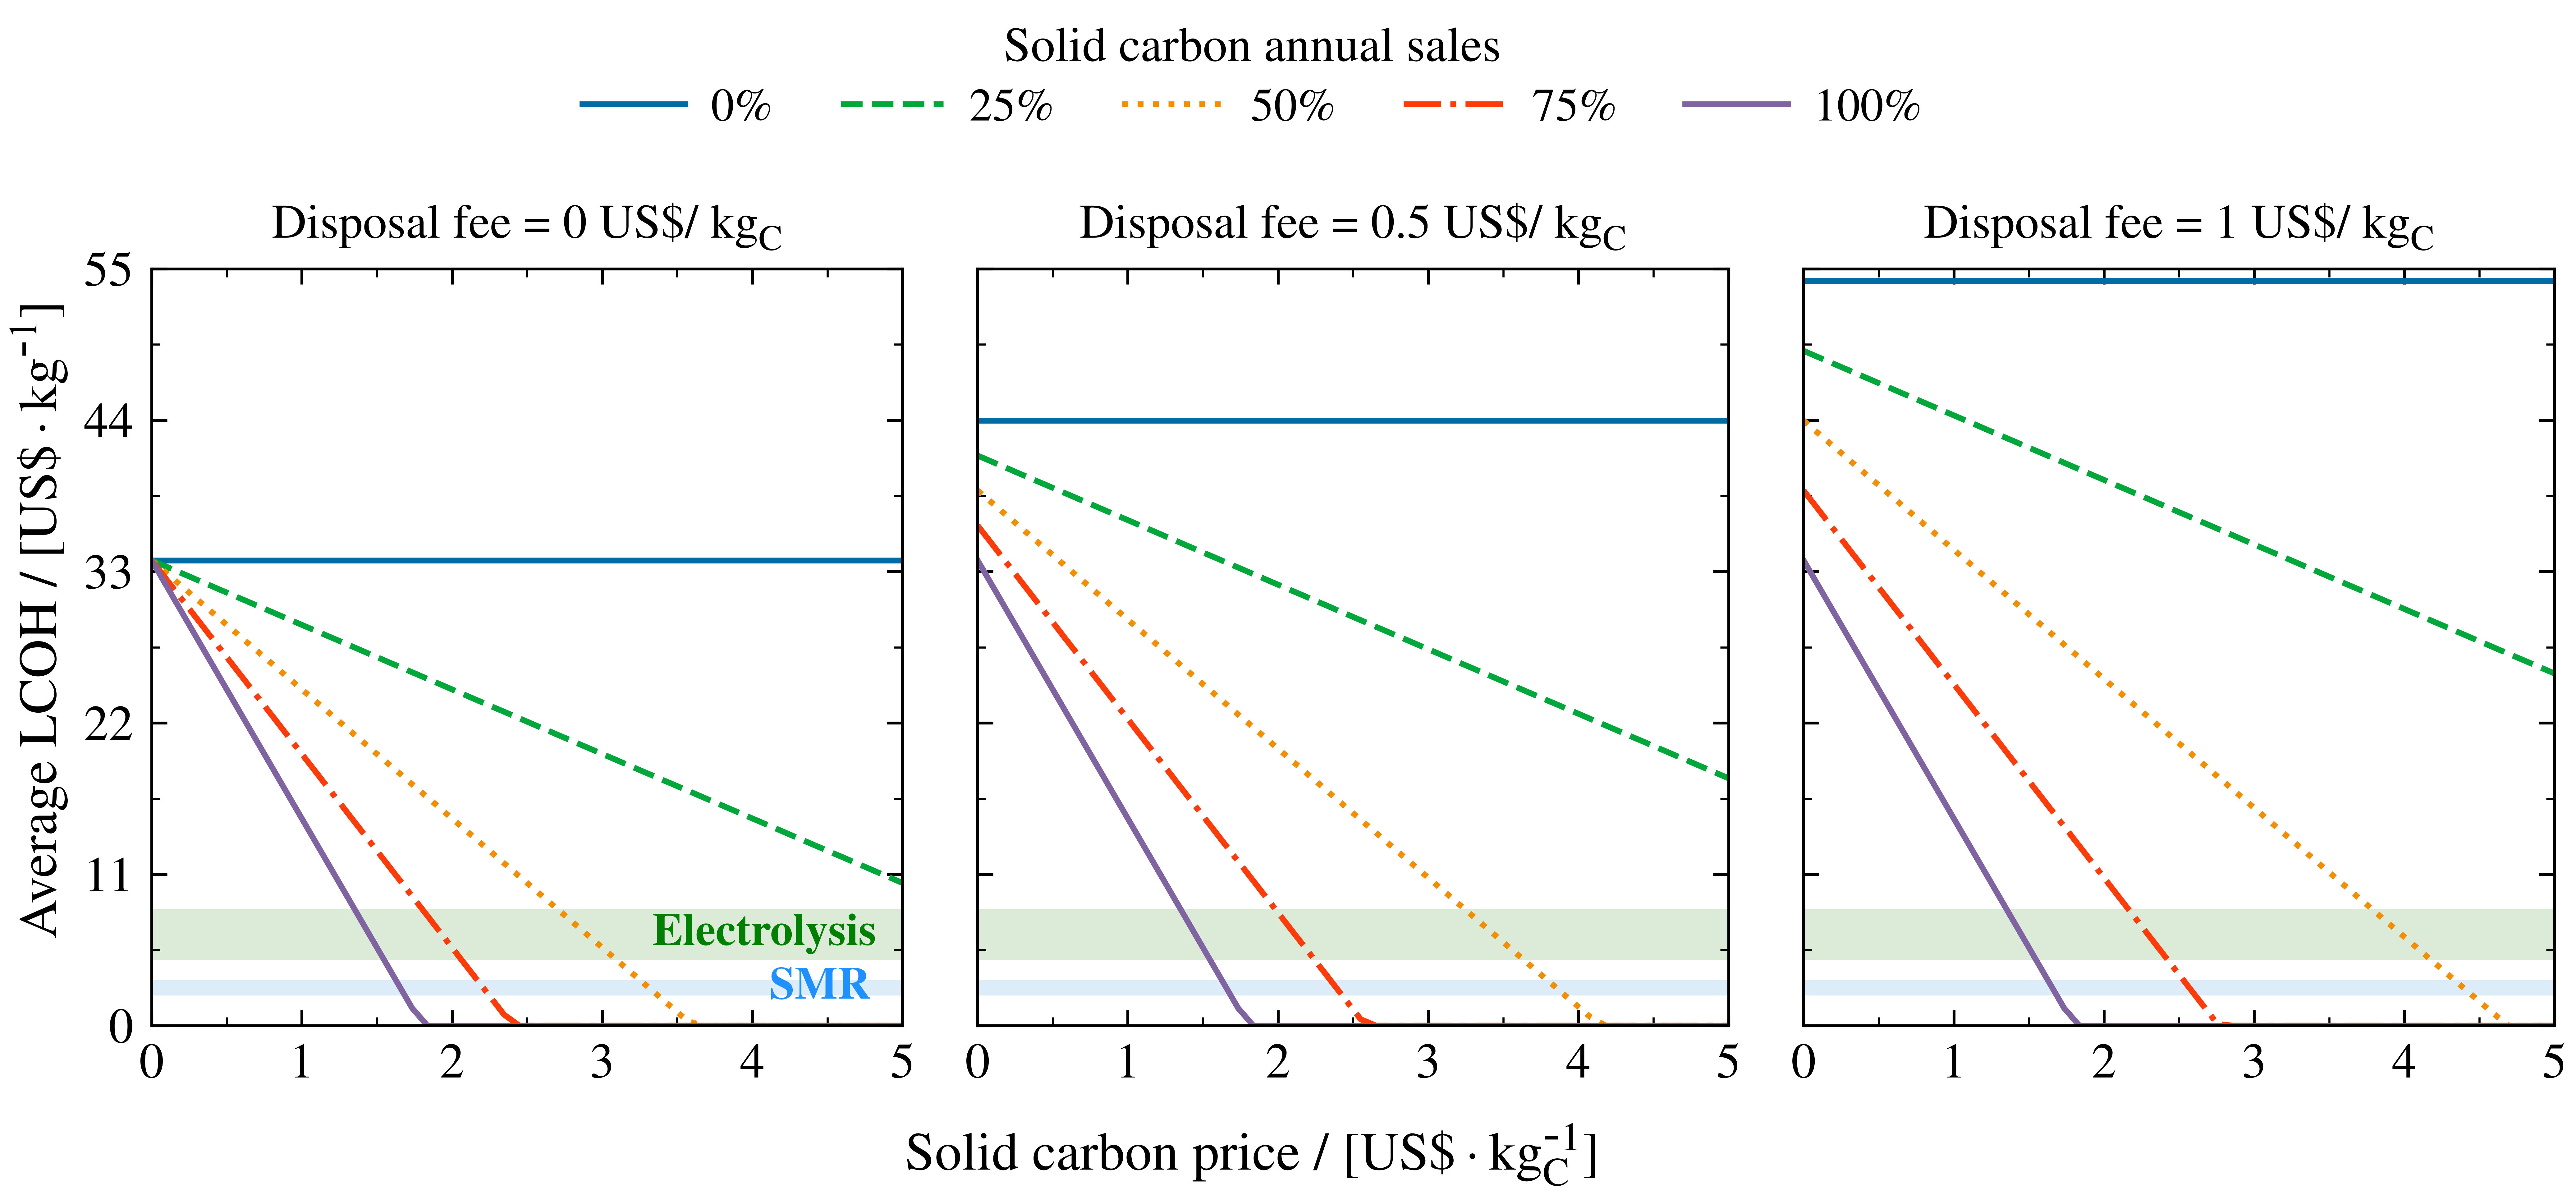

In [34]:
#Carbon price, diposal fee, sold share

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots

from copy import deepcopy
from pathlib import Path
from matplotlib.ticker import MultipleLocator


plt.style.use(["science", "ieee"])

font_scale = 1.10

tick_font = 17.5 * font_scale
axis_label_font = 19.0 * font_scale
title_font = 17.0 * font_scale
legend_font = 16.4 * font_scale
legend_title_font = 17.2 * font_scale
reference_font = 16.0 * font_scale

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "axes.titlesize": title_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

#Parametric analysis settings

carbon_prices = np.linspace(0, 5)
disposal_fees = [0.0, 0.5, 1.0]
sales_fractions = [0.00, 0.25, 0.50, 0.75, 1.00]

sales_labels = {
    0.00: r"0\%",
    0.25: r"25\%",
    0.50: r"50\%",
    0.75: r"75\%",
    1.00: r"100\%"
}

sales_colors = {
    0.00: "#006BA4",
    0.25: "#00A83B",
    0.50: "#F28E00",
    0.75: "#FF3B0A",
    1.00: "#8064A2"
}

def as_scalar(value):
    array = np.asarray(value, dtype=float)
    if array.size != 1:
        raise ValueError("Expected a scalar economic result.")
    return float(array.item())

def calculate_lcoh_curve(base_plant, sales_fraction, disposal_fee, carbon_prices):
    plant = deepcopy(base_plant)

    carbon_config = plant.plant_products["carbon"]
    disposal_config = plant.variable_opex_inputs["carbon_disposal_fee"]

    baseline_sold = as_scalar(carbon_config["production"])
    baseline_disposed = as_scalar(disposal_config["consumption"])

    total_solid_production = baseline_sold + baseline_disposed

    carbon_config["production"] = total_solid_production * sales_fraction
    disposal_config["consumption"] = total_solid_production * (1 - sales_fraction)

    disposal_config["price"] = disposal_fee
    disposal_config["std"] = 0.0

    carbon_config["std"] = 0.0

    lcoh_values = []

    for carbon_price in carbon_prices:
        carbon_config["price"] = float(carbon_price)
        lcoh = plant.calculate_levelized_cost(print_results=False)
        lcoh_values.append(as_scalar(lcoh))

    return np.asarray(lcoh_values)

#Average CSTR/PFR
results = {}

for disposal_fee in disposal_fees:
    results[disposal_fee] = {}

    for sales_fraction in sales_fractions:
        lcoh_CSTR = calculate_lcoh_curve(
            base_plant=plant_values_CSTR[idx],
            sales_fraction=sales_fraction,
            disposal_fee=disposal_fee,
            carbon_prices=carbon_prices
        )

        lcoh_PFR = calculate_lcoh_curve(
            base_plant=plant_values_PFR[idx],
            sales_fraction=sales_fraction,
            disposal_fee=disposal_fee,
            carbon_prices=carbon_prices
        )

        results[disposal_fee][sales_fraction] = (lcoh_CSTR + lcoh_PFR) / 2.0

#Comparison technologies
smr_min = 1.0
smr_max = 4.0

electrolysis_min = 4.0
electrolysis_max = 12.0


maximum_lcoh = max(
    np.max(curve)
    for fee_results in results.values()
    for curve in fee_results.values()
)

y_axis_max = max(15.0, 5.0 * np.ceil((maximum_lcoh + 0.5) / 5.0))
y_major_ticks = np.linspace(0, y_axis_max, 6)
y_major_step = y_major_ticks[1] - y_major_ticks[0]

#Three Panel Figure
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(14.4, 6.6),
    sharex=True,
    sharey=True
)

fig.patch.set_facecolor("white")

for ax, disposal_fee in zip(axes, disposal_fees):
    ax.axhspan(smr_min, smr_max, color="#DCECF8", alpha=0.98, linewidth=0, zorder=0)
    ax.axhspan(electrolysis_min, electrolysis_max, color="#DCEBD8", alpha=0.98, linewidth=0, zorder=0)

    for sales_fraction in sales_fractions:
        ax.plot(
            carbon_prices,
            results[disposal_fee][sales_fraction],
            color=sales_colors[sales_fraction],
            linewidth=2.25,
            label=sales_labels[sales_fraction],
            zorder=2
        )

    ax.set_title(
        rf"Disposal fee = {disposal_fee:g} US\$/ $\mathrm{{kg}}_{{\mathrm{{C}}}}$",
        fontsize=title_font,
        pad=12
    )

    ax.set_xlim(0, 5)
    ax.set_ylim(0, y_axis_max)

    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_minor_locator(MultipleLocator(0.5))

    ax.set_yticks(y_major_ticks)
    ax.yaxis.set_minor_locator(MultipleLocator(y_major_step / 2.0))

    ax.tick_params(axis="x", which="major", direction="in", top=True, bottom=True,
                   labelsize=tick_font, colors="black", length=6.0, width=1.1, pad=7)

    ax.tick_params(axis="y", which="major", direction="in", left=True, right=True,
                   labelsize=tick_font, colors="black", length=6.0, width=1.1, pad=7)

    ax.tick_params(axis="x", which="minor", direction="in", top=True, bottom=True,
                   colors="black", length=3.2, width=0.8)

    ax.tick_params(axis="y", which="minor", direction="in", left=True, right=True,
                   colors="black", length=3.2, width=0.8)

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.1)


axes[0].text(
    4.45,
    (smr_min + smr_max) / 2.0,
    r"\textbf{SMR}",
    color="#1E90FF",
    fontsize=reference_font,
    ha="center",
    va="center"
)

axes[0].text(
    4.08,
    (electrolysis_min + electrolysis_max) / 2.0,
    r"\textbf{Electrolysis}",
    color="green",
    fontsize=reference_font,
    ha="center",
    va="center"
)


fig.supxlabel(
    r"Solid carbon price / [US\$\,$\cdot$\,kg$_{\mathrm{C}}^{\mbox{-}1}$]",
    fontsize=axis_label_font,
    y=0.040
)

fig.supylabel(
    r"Average LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]",
    fontsize=axis_label_font,
    x=0.037
)


legend_handles, legend_labels = axes[0].get_legend_handles_labels()

legend = fig.legend(
    legend_handles,
    legend_labels,
    title=r"Solid carbon annual sales",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    ncol=5,
    frameon=False,
    fontsize=legend_font,
    handlelength=2.2,
    handletextpad=0.55,
    columnspacing=1.45,
    labelspacing=0.35
)

legend.get_title().set_fontsize(legend_title_font)

fig.subplots_adjust(
    left=0.090,
    right=0.985,
    bottom=0.170,
    top=0.785,
    wspace=0.10
)

fig.savefig("carbon_price_disposal_fee_sensitivity.pdf", format="pdf")

plt.show()

In [35]:
# MONTE CARLO DISABLED (slow) - uncomment to run
# # Monte Carlo simulations on economic variables

# import numpy as np
# import matplotlib.pyplot as plt
# from copy import deepcopy
# from scipy.optimize import brentq
# from scipy.stats import norm, truncnorm
# from openpytea.analysis import make_distribution
# from openpytea.analysis import monte_carlo
# from openpytea.plotting import plot_monte_carlo

# num_samples, batch_size, num_bins, seed = 1_000_000, 10_000, 60, 12345

# # New economic distributions

# # Carbon selling price ($/kg): lognormal (OpenPyTEA dist_id 2)
# carbon_price, carbon_std, carbon_max, carbon_min = 1.50, 1.5, 3.0, 0.50

# # Carbon disposal fee ($/kg): lognormal (OpenPyTEA dist_id 2), tail towards high values
# disposal_price, disposal_std, disposal_max, disposal_min = 0.50, 0.5, 1.0, 0.0

# # Carbon fraction sold: lognormal, tail towards high values
# sale_fraction, sale_fraction_std, sale_fraction_max, sale_fraction_min = 0.50, 0.2, 1, 0.0

# # Plant and solid flows

# def prepare_ac_plant(plant):

#     p = deepcopy(plant)

#     # Total solids in kg/day: carbon produced + spent AC catalyst
#     total_solids = (
#         float(p.plant_products["carbon"]["production"]) +
#         float(p.variable_opex_inputs["carbon_disposal_fee"]["consumption"])
#     )

#     # Baseline: 50% sold, 50% disposed
#     p.plant_products["carbon"].update({
#         "production": total_solids*sale_fraction,
#         "price": carbon_price, "std": carbon_std,
#         "max": carbon_max, "min": carbon_min
#     })

#     p.variable_opex_inputs["carbon_disposal_fee"].update({
#         "consumption": total_solids*(1-sale_fraction),
#         "price": disposal_price, "std": disposal_std,
#         "max": disposal_max, "min": disposal_min
#     })

#     return p, total_solids

# plant_PFR_AC, total_solids_PFR = prepare_ac_plant(plant_values_PFR[idx])
# plant_CSTR_AC, total_solids_CSTR = prepare_ac_plant(plant_values_CSTR[idx])


# # Sampling

# base_mc_PFR = monte_carlo(
#     plant_PFR_AC, num_samples=num_samples,
#     batch_size=batch_size, random_seed=seed
# )

# base_mc_CSTR = monte_carlo(
#     plant_CSTR_AC, num_samples=num_samples,
#     batch_size=batch_size, random_seed=seed
# )

# # Verify identical economic draws for PFR and CSTR
# shared_economic_inputs = [
#     "Fixed capital factor", "Fixed opex factor",
#     "Operator hourly rate", "Project lifetime", "Interest rate",
#     "Electricity price", "Methane Feed price", "Catalyst Feed price",
#     "Cooling Water price", "Co2 Tax price"
# ]

# for key in shared_economic_inputs:
#     if key not in base_mc_PFR["inputs"] or key not in base_mc_CSTR["inputs"]:
#         raise KeyError(f"Missing Monte Carlo input: {key}")

#     if not np.array_equal(base_mc_PFR["inputs"][key], base_mc_CSTR["inputs"][key], equal_nan=True):
#         raise ValueError(f"PFR/CSTR economic draws differ for '{key}'.")


# # Generate distributions

# def truncated_normal_quantile(u, mu, sigma, low, high):
#     a, b = (low-mu)/sigma, (high-mu)/sigma
#     return truncnorm.ppf(u, a, b, loc=mu, scale=sigma)

# def lognormal_quantile(u, mean, std, minimum, maximum, tail="high"):
#     """Quantiles ``u`` of OpenPyTEA's lognormal (dist_id 2) truncated to [minimum, maximum].

#     tail="high": long tail towards the maximum (standard lognormal).
#     tail="low":  long tail towards the minimum (lognormal mirrored at the maximum,
#                  x = maximum - Y). Quantiles still increase with ``u``.
#     sigma (of ln x) is matched to ``std``; mu is tuned so that the mean of the
#     truncated distribution equals ``mean``.
#     """
#     if tail == "low":
#         return maximum - lognormal_quantile(1 - np.asarray(u), maximum - mean, std,
#                                             0.0, maximum - minimum, tail="high")

#     sigma = np.sqrt(np.log(1 + (std / mean) ** 2))
#     log_low = np.log(minimum) if minimum > 0 else -np.inf
#     log_high = np.log(maximum)

#     def truncated_mean_gap(mu):
#         # E[x | minimum <= x <= maximum] - mean, closed form for a lognormal
#         a, b = (log_low - mu) / sigma, (log_high - mu) / sigma
#         mass = norm.cdf(b) - norm.cdf(a)
#         return np.exp(mu + sigma**2 / 2) * (norm.cdf(b - sigma) - norm.cdf(a - sigma)) / mass - mean

#     # Bracket: low mu -> truncated mean near the minimum; high mu -> near the maximum
#     mu = brentq(truncated_mean_gap, np.log(mean) - 5 * sigma - 1, log_high + 3 * sigma)
#     dist = make_distribution(2, loc=mu, scale=sigma)
#     low, high = dist.cdf(minimum), dist.cdf(maximum)
#     return dist.ppf(low + np.asarray(u) * (high - low))

# rng = np.random.default_rng(seed + 1)


# u_price = np.clip(rng.random(num_samples), 1e-12, 1-1e-12)
# u_disposal = np.clip(rng.random(num_samples), 1e-12, 1-1e-12)
# u_sale = np.clip(rng.random(num_samples), 1e-12, 1-1e-12)

# carbon_selling_price = lognormal_quantile(
#     u_price, carbon_price, carbon_std, carbon_min, carbon_max
# )

# carbon_disposal_fee = lognormal_quantile(
#     u_disposal, disposal_price, disposal_std, disposal_min, disposal_max, tail="high"
# )

# carbon_sale_fraction = lognormal_quantile(
#     u_sale, sale_fraction, sale_fraction_std, sale_fraction_min, sale_fraction_max, tail="high"
# )

# # Solid material balances

# def material_balance(total_solids):

#     sold = carbon_sale_fraction*total_solids
#     disposed = (1-carbon_sale_fraction)*total_solids

#     np.testing.assert_allclose(sold + disposed, total_solids)

#     return {
#         "sold": sold,
#         "disposed": disposed,
#         "total_solids": np.full(num_samples, total_solids)
#     }

# streams_PFR = material_balance(total_solids_PFR)
# streams_CSTR = material_balance(total_solids_CSTR)



# # New lcoh

# def evaluate_ac_mc(plant, base_mc, streams, name):

#     inputs = {key: np.asarray(value).copy() for key, value in base_mc["inputs"].items()}

#     # New independent carbon-related inputs
#     inputs["Carbon product price"] = carbon_selling_price.copy()
#     inputs["Carbon Disposal Fee price"] = carbon_disposal_fee.copy()
#     inputs["Carbon production"] = streams["sold"].copy()
#     inputs["Carbon Disposal Fee consumption"] = streams["disposed"].copy()

#     inputs["Carbon sale fraction"] = carbon_sale_fraction.copy()
#     inputs["Total solids (kg/day)"] = streams["total_solids"].copy()

#     lcoh_samples = np.empty(num_samples)

#     for start in range(0, num_samples, batch_size):

#         end = min(start + batch_size, num_samples)
#         s = slice(start, end)
#         p = deepcopy(plant)

#         # Operator hourly rate
#         p.operator_hourly_rate["rate"] = inputs["Operator hourly rate"][s]

#         # Project assumptions
#         changes = {
#             "project_lifetime": inputs["Project lifetime"][s],
#             "interest_rate": inputs["Interest rate"][s]
#         }

#         if "Plant utilization" in inputs:
#             changes["plant_utilization"] = inputs["Plant utilization"][s]

#         if "Tax rate" in inputs:
#             changes["tax_rate"] = inputs["Tax rate"][s]

#         p.update_configuration(changes)

#         # Variable OPEX
#         for item in plant.variable_opex_inputs:
#             label = item.replace("_", " ").title()

#             p.variable_opex_inputs[item]["price"] = inputs[f"{label} price"][s]
#             p.variable_opex_inputs[item]["consumption"] = inputs[f"{label} consumption"][s]

#         # Products and revenues
#         for product in plant.plant_products:
#             label = product.replace("_", " ").title()

#             if f"{label} product price" in inputs:
#                 p.plant_products[product]["price"] = inputs[f"{label} product price"][s]

#             p.plant_products[product]["production"] = inputs[f"{label} production"][s]

#         # OpenPyTEA economic calculations
#         p.calculate_fixed_capital(fc=inputs["Fixed capital factor"][s])
#         p.calculate_variable_opex()
#         p.calculate_fixed_opex(fp=inputs["Fixed opex factor"][s])
#         p.calculate_cash_flow()
#         p.calculate_levelized_cost()

#         # Unclipped LCOH: OpenPyTEA floors the LCOP at 0, but negative values
#         # (carbon revenue above all costs) are kept here
#         disc_capex, disc_opex, disc_side_rev, disc_prod = p._discounted_totals()
#         lcoh_samples[s] = np.ravel((disc_capex + disc_opex - disc_side_rev) / disc_prod)

#     if not np.all(np.isfinite(lcoh_samples)):
#         raise ValueError(f"Non-finite LCOH values in {name}")

#     return {
#         "name": name,
#         "metrics": {"LCOP": lcoh_samples},
#         "inputs": inputs,
#         "num_samples": num_samples,
#         "additional_capex": False,
#         "currency": base_mc.get("currency", r"\$")
#     }


# mc_results_PFR_AC = evaluate_ac_mc(
#     plant_PFR_AC, base_mc_PFR, streams_PFR, "PFR - Activated Carbon"
# )

# mc_results_CSTR_AC = evaluate_ac_mc(
#     plant_CSTR_AC, base_mc_CSTR, streams_CSTR, "CSTR - Activated Carbon"
# )

# # Average LCOH

# lcoh_mc_average = (
#     mc_results_PFR_AC["metrics"]["LCOP"] +
#     mc_results_CSTR_AC["metrics"]["LCOP"]
# ) / 2

# mc_results_average_AC = deepcopy(mc_results_PFR_AC)
# mc_results_average_AC["name"] = "Average PFR-CSTR - Activated Carbon"
# mc_results_average_AC["metrics"] = {"LCOP": lcoh_mc_average}

# # Plot

# with plt.style.context("default"):

#     fig, ax = plot_monte_carlo(
#         mc_results_average_AC,
#         metric="LCOP",
#         bins=num_bins,
#         figsize=(8, 5),
#         show=False
#     )

#     fig.set_dpi(120)
#     fig.set_facecolor("white")
#     ax.set_facecolor("white")

#     ax.set_title(
#         f"Monte Carlo LCOH - Activated carbon ({temperatures[idx]} °C)",
#         fontsize=14, pad=12
#     )

#     ax.set_xlabel(r"Average LCOH / [US$ $\cdot$ kg$^{-1}$]", fontsize=13, labelpad=10)
#     ax.set_ylabel("Probability density", fontsize=13, labelpad=8)

#     ax.tick_params(axis="both", which="major", direction="in",
#                    top=True, right=True, labelsize=11, length=5)

#     ax.tick_params(axis="both", which="minor", direction="in",
#                    top=True, right=True, length=3)

#     ax.minorticks_on()
#     ax.legend(loc="upper right", fontsize=11, frameon=True)

#     fig.tight_layout()
#     plt.show()


In [36]:
#SI: - MC INPUTS AC
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots

from pathlib import Path
from openpytea.plotting import plot_monte_carlo_inputs

plt.style.use(["science", "ieee"])

font_scale = 1.10
tick_font = 13.5 * font_scale
title_font = 14.5 * font_scale
axis_label_font = 14.0 * font_scale

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.titlesize": title_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

#Select MC inputs
mc_inputs = mc_results_average_AC["inputs"]

def normalize_key(key):
    return " ".join(str(key).lower().replace("_", " ").replace("-", " ").split())

parameter_groups = [
    ("Fixed capital factor",),
    ("Fixed opex factor",),
    ("Operator hourly rate",),
    ("Project lifetime",),
    ("Interest rate",),
    ("Electricity price",),
    ("Methane Feed price", "Methane price"),
    ("Catalyst Feed price", "Catalyst price"),
    ("Cooling Water price", "Cooling water price"),
    ("CO2 Tax price", "Co2 Tax price"),
    ("Carbon product price", "Carbon selling price"),
    ("Carbon Disposal Fee price", "Carbon disposal fee"),
    ("Carbon sale fraction", "Fraction sold", "Sale fraction")
]

selected_inputs = {}

for aliases in parameter_groups:
    alias_norm = [normalize_key(alias) for alias in aliases]
    match = next((key for key in mc_inputs if normalize_key(key) in alias_norm), None)

    if match is not None:
        selected_inputs[match] = mc_inputs[match]

if len(selected_inputs) != len(parameter_groups):
    raise KeyError("Some Monte Carlo economic inputs are missing.")

mc_results_plot = dict(mc_results_average_AC)
mc_results_plot["inputs"] = selected_inputs

#Plot
fig, axes = plot_monte_carlo_inputs(mc_results_plot, category="economic", bins=40, show=False)
fig.set_facecolor("white")

if getattr(fig, "_suptitle", None) is not None:
    fig._suptitle.set_visible(False)

for txt in fig.texts:
    if txt.get_text().strip().lower() == "economic parameters":
        txt.set_visible(False)

label_map = {
    "fixed capital factor": r"Fixed capital factor / [-]",
    "fixed opex factor": r"Fixed OPEX factor / [-]",
    "operator hourly rate": r"Operator hourly rate / [US\$·h$^{-1}$]",
    "project lifetime": r"Project lifetime / [years]",
    "interest rate": r"Interest rate / [-]",
    "electricity price": r"Electricity price / [US\$·kWh$^{-1}$]",
    "methane feed price": r"Methane feed price / [US\$·kg$^{-1}$]",
    "methane price": r"Methane feed price / [US\$·kg$^{-1}$]",
    "catalyst feed price": r"Catalyst price / [US\$·kg$^{-1}$]",
    "catalyst price": r"Catalyst price / [US\$·kg$^{-1}$]",
    "cooling water price": r"Cooling water price / [US\$·MJ$^{-1}$]",
    "co2 tax price": r"$\mathrm{CO}_2$ tax rate / [US\$·kg$^{-1}$]",
    "carbon product price": r"Carbon selling price / [US\$·kg$^{-1}$]",
    "carbon selling price": r"Carbon selling price / [US\$·kg$^{-1}$]",
    "carbon disposal fee price": r"Carbon disposal fee / [US\$·kg$^{-1}$]",
    "carbon disposal fee": r"Carbon disposal fee / [US\$·kg$^{-1}$]",
    "carbon sale fraction": r"Fraction sold / [-]",
    "fraction sold": r"Fraction sold / [-]",
    "sale fraction": r"Fraction sold / [-]"
}

axes_flat = np.asarray(axes).ravel()

for ax in axes_flat:
    if not ax.get_visible() or not ax.axison:
        continue

    current_title = ax.get_title()
    current_title_norm = normalize_key(current_title)
    xlabel = label_map.get(current_title_norm, current_title)

    ax.set_title("")
    ax.set_xlabel(xlabel, fontsize=axis_label_font, labelpad=8)
    ax.xaxis.label.set_fontsize(axis_label_font)
    ax.yaxis.label.set_fontsize(axis_label_font)
    ax.set_facecolor("white")

    ax.tick_params(axis="both", which="major", direction="in", top=True, bottom=True, left=True, right=True,
                   labelsize=tick_font, colors="black", length=5.5, width=1.0, pad=5)

    ax.minorticks_on()

    ax.tick_params(axis="both", which="minor", direction="in", top=True, bottom=True, left=True, right=True,
                   colors="black", length=3.0, width=0.8)

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.0)

n_parameters = len(selected_inputs)
n_rows = int(np.ceil(n_parameters / 3))

fig.set_size_inches(14.4, 11.4 * n_rows / 4)

#Layout
fig.subplots_adjust(
    left=0.070,
    right=0.985,
    bottom=0.070,
    top=0.975,
    wspace=0.28,
    hspace=0.40
)

fig.savefig("mc_inputs_AC.pdf", format="pdf")

plt.show()


NameError: name 'mc_results_average_AC' is not defined

In [ ]:
# MONTE CARLO DISABLED (slow) - uncomment to run
# # Save Monte Carlo results
# import json
# from pathlib import Path

# # Find project root
# try:
#     start_dir = Path(__file__).resolve().parent
# except NameError:
#     start_dir = Path.cwd()

# project_root = next(
#     (p for p in [start_dir, *start_dir.parents]
#      if all((p / folder).is_dir() for folder in ["catalysts", "benchmarks"])),
#     None
# )

# if project_root is None:
#     raise FileNotFoundError("Project root not found.")

# # Output directory
# results_dir = project_root / "catalysts" / "ac" / "results" / "tea"
# results_dir.mkdir(parents=True, exist_ok=True)

# mc_file = results_dir / "LCOH_MonteCarlo.json"

# # Prepare Monte Carlo results
# mc_export = {
#     "name": "Activated Carbon",
#     "temperature": float(temperatures[idx]),
#     "metrics": {
#         "LCOP": lcoh_mc_average.tolist()
#     },
#     # Sampled carbon-related inputs, for plotting their distributions
#     "inputs": {
#         "Carbon selling price [US$/kg]": carbon_selling_price.tolist(),
#         "Carbon disposal fee [US$/kg]": carbon_disposal_fee.tolist(),
#         "Carbon fraction sold [-]": carbon_sale_fraction.tolist(),
#     }
# }

# # Save JSON
# with open(mc_file, "w") as f:
#     json.dump(mc_export, f, indent=4)

# print(f"JSON saved in: {mc_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\ACMP\Results_TEA\LCOH_MonteCarlo.json
